# Supplementary studies

How much does the allocation depend on our assumptions? We keep the main notebook's method and examine one choice at a time, then test combinations of limits.

| Study | Question |
|:--|:--|
| 1. Allocation limits | How much do the weights change if we move the limits? |
| 2. Data source | How different are the Bloomberg and earlier Yahoo returns? |
| 3. Historical performance | How do the alternative allocations behave over the same period? |
| 4. Estimation window | What happens when we estimate weights using earlier data? |
| 5. Trading costs | How much do transaction costs affect the results? |
| 6. Sharpe uncertainty | How precise is the historical Sharpe estimate? |
| 7. Frontier | How much estimated return is available at different risk levels? |
| 8. Return inputs | Do modest changes to mean estimates move the weights? |
| 9. Stress tests | Which scenarios and holdings drive losses? |
| 10. Expected shortfall | How large are the worst historical monthly losses? |
| 11. Weight-change impact | Do different weights materially change returns, risk or stress losses? |
| 12. Rolling volatility | How does realized risk change through time? |
| 13. Return attribution | Which ETFs and fees account for historical dollar profit? |
| Appendix | Does a calculation using dollar holdings reproduce the backtest? |

The calculations use the same Bloomberg inputs as `round1_analysis.ipynb`. Tables and charts are saved in `studies/`; charts are available as PNG and PDF for the report. The main allocation is unchanged.

## Inputs and calculation functions

The current allocation uses 60 monthly returns, October 2021–September 2026. For each sensitivity test, we change the stated assumption and keep the other inputs fixed.

Portfolio volatility and each ETF's share of portfolio risk are calculated from the annual covariance matrix $\Sigma$

$$\sigma_p=\sqrt{w^\top\Sigma w}$$

$$RC_i=\frac{w_i(\Sigma w)_i}{w^\top\Sigma w}$$

The functions below apply the same long-only optimization and policy limits as the main notebook. Several starting portfolios help assess numerical stability; they do not prove a global optimum.

In [1]:
from pathlib import Path
from itertools import product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from IPython.display import display, Markdown

# Input paths are relative to the notebook folder.
ROOT = Path.cwd()
DATA = ROOT / "data"
RESULTS = ROOT / "results"
STUDIES = ROOT / "studies"
RESULTS.mkdir(exist_ok=True)
STUDIES.mkdir(exist_ok=True)

CAPITAL = 100_000_000
TARGET_VOLATILITY = 0.08
TRADING_COST = 0.001
ASSETS = ["SPY", "VWO", "EEMV", "DBC", "SCHD", "VGSH", "STIP"]
FIT_START = "2021-10"
FIT_END = "2026-09"
BACKTEST_START = "2016-11"
POLICY = {
    "risk_cap": 0.40,
    "capital_cap": 0.35,
    "equity_risk_cap": 0.65,
    "building_block_floor": 0.05,
    "bond_floor": 0.20,
}
GROUPS = {
    "US": ["SPY", "SCHD"],
    "EM": ["VWO", "EEMV"],
    "commodities": ["DBC"],
    "VGSH": ["VGSH"],
    "STIP": ["STIP"],
}
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})

ASSET_COLORS = {"SPY": "#315b83", "VWO": "#7587aa", "EEMV": "#7caac1",
                "DBC": "#c28d48", "SCHD": "#8b7a9d", "VGSH": "#8cac98", "STIP": "#b9cedb"}

def save_chart(figure, filename):
    figure.tight_layout()
    figure.savefig(STUDIES / (filename + ".png"), dpi=180, bbox_inches="tight")
    figure.savefig(STUDIES / (filename + ".pdf"), bbox_inches="tight")
    plt.show()

STRATEGY_COLORS = {"Trained MVO": "#315b83", "Equal weight": "#bd904d",
                   "Trained risk parity": "#78a69b"}

def readable_scenario(label):
    if label == "Baseline":
        return "Baseline"
    parameter, value = label.split("=")
    names = {"risk_cap": "ETF risk cap", "building_block_floor": "All block minimums",
             "bond_floor": "Combined bond minimum", "capital_cap": "ETF weight cap",
             "equity_risk_cap": "Combined equity risk cap"}
    return f"{names.get(parameter, parameter)}: {float(value):.1%}"

In [2]:
prices = pd.read_csv(DATA / "month_end_prices.csv", index_col="month", parse_dates=True)[ASSETS]
returns = prices.pct_change(fill_method=None).iloc[1:]
training = returns.loc[FIT_START:FIT_END]
assert len(training) == 60 and np.isfinite(returns.to_numpy()).all()

annual_mean = training.mean() * 12
annual_covariance = training.cov() * 12
annual_inputs = pd.DataFrame({
    "annual_mean_input": annual_mean,
    "annual_volatility": training.std(ddof=1) * np.sqrt(12),
})

In [3]:
def portfolio_volatility(weights, covariance):
    return float(np.sqrt(weights @ covariance @ weights))


def risk_shares(weights, covariance):
    variance = weights @ covariance @ weights
    return weights * (covariance @ weights) / variance


def risk_share_gradient(weights, covariance):
    # Analytic derivatives help SLSQP handle the nonlinear risk-share limits.
    marginal_covariance = covariance @ weights
    variance = weights @ marginal_covariance
    numerator_gradient = np.diag(marginal_covariance) + np.diag(weights) @ covariance
    variance_gradient = 2 * marginal_covariance
    return (numerator_gradient / variance
            - np.outer(weights * marginal_covariance, variance_gradient) / variance**2)


def policy_margins(weights, covariance, assets, policy):
    # Nonnegative margins mean the inequalities are satisfied.
    contributions = risk_shares(weights, covariance)
    equity_mask = np.array([ticker in {"SPY", "VWO", "EEMV", "SCHD"} for ticker in assets])
    margins = {
        "long_only": float(np.min(weights)),
        "capital_cap": float(policy["capital_cap"] - np.max(weights)),
        "risk_cap": float(policy["risk_cap"] - np.max(contributions)),
        "equity_risk_cap": float(policy["equity_risk_cap"] - contributions[equity_mask].sum()),
        "bond_floor": float(sum(weights[i] for i, ticker in enumerate(assets)
                                if ticker in {"VGSH", "STIP"}) - policy["bond_floor"]),
    }
    for group, tickers in GROUPS.items():
        exposure = sum(weights[i] for i, ticker in enumerate(assets) if ticker in tickers)
        floor = policy.get("floor_" + group, policy["building_block_floor"])
        margins[group + "_floor"] = float(exposure - floor)
    return pd.Series(margins)

In [4]:
def optimize_weights(sample, policy, target=TARGET_VOLATILITY,
                     seeds=(12, 91), random_starts=100, warm_starts=()):
    assets = list(sample.columns)
    count = len(assets)
    covariance = sample.cov().to_numpy() * 12
    means = sample.mean().to_numpy() * 12
    equity_mask = np.array([ticker in {"SPY", "VWO", "EEMV", "SCHD"} for ticker in assets], dtype=float)

    constraints = [
        {"type": "eq", "fun": lambda w: w.sum() - 1,
         "jac": lambda w: np.ones(count)},
        {"type": "eq", "fun": lambda w: (w @ covariance @ w) / target**2 - 1,
         "jac": lambda w: 2 * covariance @ w / target**2},
        {"type": "ineq", "fun": lambda w: policy["risk_cap"] - risk_shares(w, covariance),
         "jac": lambda w: -risk_share_gradient(w, covariance)},
        {"type": "ineq", "fun": lambda w: policy["equity_risk_cap"] - equity_mask @ risk_shares(w, covariance),
         "jac": lambda w: -equity_mask @ risk_share_gradient(w, covariance)},
    ]
    for group, tickers in {**GROUPS, "bonds": ["VGSH", "STIP"]}.items():
        mask = np.array([ticker in tickers for ticker in assets], dtype=float)
        floor = (policy["bond_floor"] if group == "bonds"
                 else policy.get("floor_" + group, policy["building_block_floor"]))
        # Capture each group's mask and floor separately in these functions.
        constraints.append({"type": "ineq", "fun": lambda w, m=mask, f=floor: m @ w - f,
                            "jac": lambda w, m=mask: m})

    solutions = []
    diagnostics = []
    for seed in seeds:
        generator = np.random.default_rng(seed)
        starts = list(warm_starts) + list(generator.dirichlet(np.ones(count), random_starts))
        valid = []
        for initial_weights in starts:
            solution = minimize(
                fun=lambda w: -means @ w, x0=initial_weights, jac=lambda w: -means,
                bounds=[(0, policy["capital_cap"])] * count,
                constraints=constraints, method="SLSQP",
                options={"ftol": 1e-11, "maxiter": 500},
            )
            candidate = solution.x
            feasible = (abs(candidate.sum() - 1) < 1e-7
                        and abs(portfolio_volatility(candidate, covariance) - target) < 1e-7
                        and policy_margins(candidate, covariance, assets, policy).min() >= -1e-7)
            if solution.success and feasible:
                valid.append(solution)
        diagnostics.append({"seed": seed, "starts": len(starts), "verified_solutions": len(valid),
                            "best_mean_return": -min(s.fun for s in valid) if valid else np.nan})
        solutions.extend(valid)
    if not solutions:
        raise RuntimeError("No verified feasible allocation found; do not substitute arbitrary weights.")
    best = min(solutions, key=lambda solution: solution.fun)
    return best.x, pd.DataFrame(diagnostics)

## 1. How much do the weights depend on the limits?

We keep the ETF universe, 60-month input window, return objective and 8% volatility target fixed. The baseline is the policy used in the main notebook.

| Limit | Baseline |
|:--|--:|
| Maximum risk share per ETF | 40% |
| Maximum capital weight per ETF | 35% |
| Maximum combined equity risk share | 65% |
| Minimum capital in each building block | 5% |
| Minimum combined VGSH and STIP capital | 20% |

**Step 1:** Solve the baseline and define nearby limits. **Step 2:** Re-optimize all weights for each specification. **Step 3:** Compare the resulting weights with the baseline.

The 108 specifications consist of one baseline, 17 changes to common limits, ten changes to individual minimums and 80 combinations. Each sensitivity optimization uses 48 starting portfolios across two seeds. Weight comparisons use the exact optimizer solution before rounding.

The fraction of capital that moves between ETFs is

$$\text{capital reassigned}=\frac12\sum_i\left|w_i-w_i^{baseline}\right|$$

Moving 2% of capital from one ETF to another counts as 2% reassigned. We also record the largest change in any single ETF's weight.

In [5]:
baseline_weights, baseline_diagnostics = optimize_weights(training, POLICY)
specifications = [("Baseline", "baseline", POLICY.copy())]
def add_specification(label, kind, **changes):
    specifications.append((label, kind, POLICY | changes))

variations = {
    "risk_cap": [0.35, 0.375, 0.425, 0.45],
    "building_block_floor": [0.025, 0.075],
    "bond_floor": [0.15, 0.25, 0.30],
    "capital_cap": [0.30, 0.325, 0.375, 0.40],
    "equity_risk_cap": [0.55, 0.60, 0.70, 0.75],
}
for parameter, limits in variations.items():
    for limit in limits:
        add_specification(f"{parameter}={limit:.3f}", "one_limit", **{parameter: limit})
for group in GROUPS:
    for limit in [0.025, 0.075]:
        add_specification(f"{group} minimum={limit:.3f}", "individual_floor", **{"floor_" + group: limit})
for risk_cap, floor, capital_cap, equity_cap in product(
    [0.35, 0.40, 0.45], [0.025, 0.05, 0.075], [0.30, 0.35, 0.40], [0.60, 0.65, 0.70]
):
    candidate_policy = POLICY | {"risk_cap": risk_cap, "building_block_floor": floor,
                                "capital_cap": capital_cap, "equity_risk_cap": equity_cap}
    if candidate_policy != POLICY:
        specifications.append((f"Joint {len(specifications)}", "joint", candidate_policy))
assert len(specifications) == 108

### Baseline reference

These are the rounded target weights used in the main notebook. The sensitivity tests below compare exact solutions so that rounding does not affect the comparison.

In [6]:
exact_weights, solver_diagnostics = baseline_weights, baseline_diagnostics
covariance = annual_covariance.to_numpy()

def acceptable_rounding(weights):
    volatility = portfolio_volatility(weights, covariance)
    return (abs(weights.sum() - 1) < 1e-12
            and 0.07 <= volatility <= TARGET_VOLATILITY + 1e-10
            and policy_margins(weights, covariance, ASSETS, POLICY).min() >= -1e-10)

target_weights = np.round(exact_weights, 4)
target_weights[-1] = 1 - target_weights[:-1].sum()
if not acceptable_rounding(target_weights):
    # Try adjacent 0.01 percentage-point grid values, not a new portfolio search.
    lower_weights = np.floor(exact_weights * 10_000) / 10_000
    feasible_roundings = []
    for increments in product([0, 1], repeat=len(ASSETS)):
        candidate = lower_weights + np.array(increments) / 10_000
        if acceptable_rounding(candidate):
            feasible_roundings.append(candidate)
    if not feasible_roundings:
        raise RuntimeError("No nearby rounded allocation satisfies the policy limits.")
    target_weights = min(feasible_roundings, key=lambda w: np.sum((w - exact_weights)**2))

allocation = pd.DataFrame({
    "exact_weight": exact_weights,
    "target_weight": target_weights,
    "risk_share": risk_shares(target_weights, covariance),
    "target_value_usd": target_weights * CAPITAL,
}, index=ASSETS)
allocation.index.name = "ticker"

display(allocation.loc[allocation["target_weight"] > 1e-8, ["target_weight", "risk_share"]]
        .rename(columns={"target_weight": "Main target weight", "risk_share": "Risk share"})
        .style.format("{:.2%}"))

,Main target weight,Risk share
ticker,,
SPY,26.08%,40.00%
EEMV,9.66%,8.62%
DBC,26.95%,39.99%
SCHD,3.28%,4.79%
VGSH,5.00%,0.37%
STIP,29.03%,6.23%


In [7]:
covariance = annual_covariance.to_numpy()
sensitivity_rows = []
sensitivity_weights = {}
for number, (label, kind, policy) in enumerate(specifications):
    weights, diagnostics = optimize_weights(
        training, policy, seeds=(17, 83), random_starts=22,
        warm_starts=(baseline_weights, np.ones(len(ASSETS)) / len(ASSETS)),
    )
    direct_returns = training.to_numpy() @ weights
    direct_variance = np.var(direct_returns, ddof=1) * 12
    direct_risk = np.array([
        weights[i] * np.cov(training.iloc[:, i], direct_returns, ddof=1)[0, 1] * 12 / direct_variance
        for i in range(len(ASSETS))
    ])
    assert np.max(abs(direct_risk - risk_shares(weights, covariance))) < 1e-10
    assert abs(np.sqrt(direct_variance) - TARGET_VOLATILITY) < 1e-7
    assert policy_margins(weights, covariance, ASSETS, policy).min() >= -1e-7
    seed_gap = diagnostics["best_mean_return"].max() - diagnostics["best_mean_return"].min()
    assert diagnostics["best_mean_return"].notna().all() and seed_gap < 1e-9
    row = {"scenario": label, "kind": kind, **policy,
           **dict(zip(ASSETS, weights)),
           "max_weight_change_pp": float(np.max(abs(weights - baseline_weights)) * 100),
           "capital_reassigned_pct": float(np.abs(weights - baseline_weights).sum() / 2 * 100),
           "estimated_mean": float(annual_mean.to_numpy() @ weights),
           "estimated_volatility": float(np.sqrt(direct_variance)),
           "seed_objective_gap": float(seed_gap),
           "verified_solutions": int(diagnostics["verified_solutions"].sum())}
    row.update({ticker + "_risk": float(direct_risk[i]) for i, ticker in enumerate(ASSETS)})
    sensitivity_rows.append(row)
    sensitivity_weights[label] = weights
sensitivity = pd.DataFrame(sensitivity_rows).set_index("scenario")
sensitivity.to_csv(STUDIES / "constraint_sensitivity.csv")

individual_changes = sensitivity.loc[sensitivity["kind"] != "joint", ASSETS + ["capital_reassigned_pct"]]
display(individual_changes.rename(index=readable_scenario, columns={"capital_reassigned_pct": "Capital moved (%)"})
        .style.format({**{a: "{:.2%}" for a in ASSETS}, "Capital moved (%)": "{:.2f}"}))

,SPY,VWO,EEMV,DBC,SCHD,VGSH,STIP,Capital moved (%)
scenario,,,,,,,,
Baseline,26.08%,0.00%,9.65%,26.96%,3.28%,5.00%,29.03%,0.00
ETF risk cap: 35.0%,22.57%,0.00%,12.17%,24.56%,7.87%,5.00%,27.84%,7.10
ETF risk cap: 37.5%,24.30%,0.00%,10.95%,25.77%,5.61%,5.00%,28.36%,3.64
ETF risk cap: 42.5%,27.92%,0.00%,8.27%,28.13%,0.83%,5.00%,29.85%,3.83
ETF risk cap: 45.0%,29.83%,0.00%,5.00%,29.19%,0.00%,10.77%,25.20%,11.76
All block minimums: 2.5%,26.10%,0.00%,9.60%,26.93%,3.03%,2.50%,31.84%,2.82
All block minimums: 7.5%,26.07%,0.00%,9.70%,26.98%,3.52%,7.50%,26.22%,2.82
Combined bond minimum: 15.0%,26.08%,0.00%,9.65%,26.96%,3.28%,5.00%,29.03%,0.00
Combined bond minimum: 25.0%,26.08%,0.00%,9.65%,26.96%,3.28%,5.00%,29.03%,0.00


### Changing the risk cap

Each column below is a newly optimized portfolio. The colours show capital weights; the horizontal labels show the maximum permitted risk share per ETF.

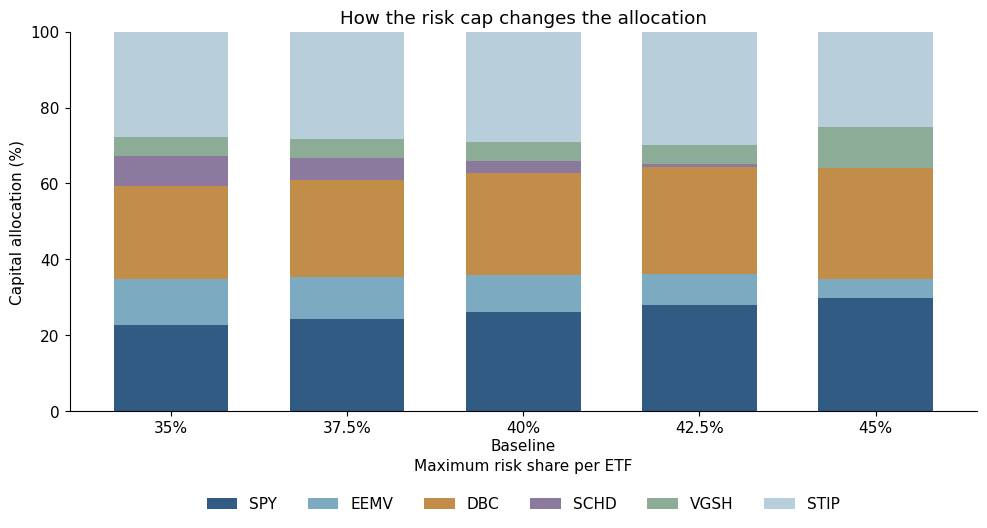

In [8]:
selected = ["risk_cap=0.350", "risk_cap=0.375", "Baseline", "risk_cap=0.425", "risk_cap=0.450"]
visible_assets = [ticker for ticker in ["SPY", "VWO", "EEMV", "DBC", "SCHD", "VGSH", "STIP"]
                  if sensitivity.loc[selected, ticker].max() > 1e-8]
chart = sensitivity.loc[selected, visible_assets].copy()
chart.index = ["35%", "37.5%", "40%\nBaseline", "42.5%", "45%"]
figure, axis = plt.subplots(figsize=(10, 5.5))
(chart * 100).plot.bar(stacked=True, ax=axis, width=0.65, rot=0,
                      color=[ASSET_COLORS[ticker] for ticker in visible_assets])
axis.set(title="How the risk cap changes the allocation", ylim=(0, 100),
         xlabel="Maximum risk share per ETF", ylabel="Capital allocation (%)")
axis.legend(ncol=len(visible_assets), frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.19))
save_chart(figure, "risk_cap_allocations")

### Which individual limits make a difference?

This chart shows changes that move more than 0.01% of capital after changing one limit. The full table above includes the changes that have little or no effect.

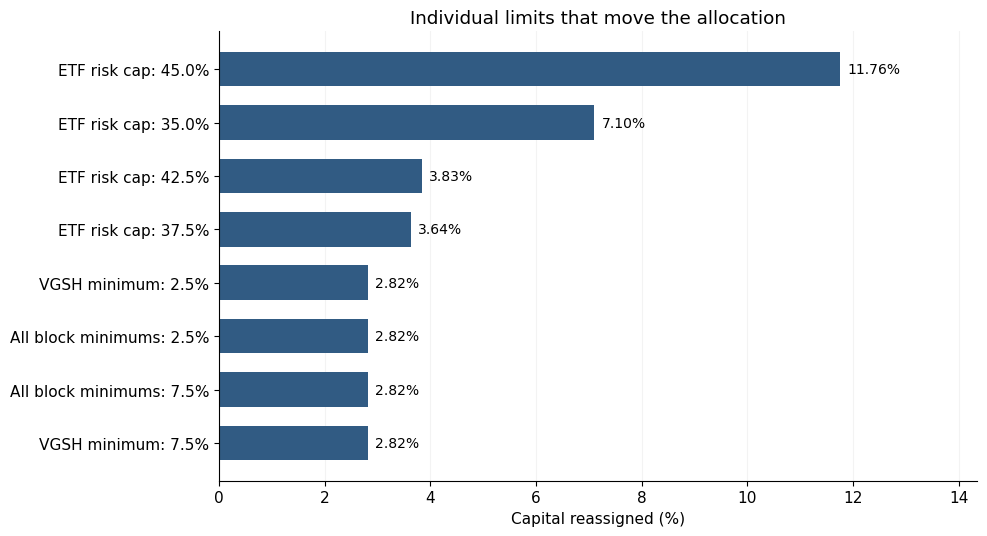

In [9]:
single_changes = sensitivity.loc[sensitivity["kind"].isin(["one_limit", "individual_floor"])]
largest_single_changes = single_changes.loc[single_changes["capital_reassigned_pct"] > 0.01].sort_values("capital_reassigned_pct")
figure, axis = plt.subplots(figsize=(10, 5.5))
bars = axis.barh([readable_scenario(label) for label in largest_single_changes.index],
                 largest_single_changes["capital_reassigned_pct"], color="#315b83", height=0.65)
axis.bar_label(bars, fmt="%.2f%%", padding=5, fontsize=10)
axis.set(title="Individual limits that move the allocation", xlabel="Capital reassigned (%)")
axis.set_xlim(0, largest_single_changes["capital_reassigned_pct"].max() * 1.22)
axis.grid(axis="x", alpha=0.15)
axis.set_axisbelow(True)
save_chart(figure, "individual_limit_sensitivity")

In [10]:
nearby = sensitivity.loc[["risk_cap=0.375", "risk_cap=0.425"], "capital_reassigned_pct"]
largest_joint = sensitivity.loc[sensitivity["kind"] == "joint", "capital_reassigned_pct"].max()
display(Markdown(
    f"Moving the risk cap from **40% to 37.5%** reassigns **{nearby.iloc[0]:.2f}%** of capital; "
    f"moving it to **42.5%** reassigns **{nearby.iloc[1]:.2f}%**. "
    f"The largest tested change to several limits together reassigns **{largest_joint:.2f}%**.\n\n"
    "The risk cap and VGSH minimum affect the allocation. Several other limits do not bind at the baseline. "
    "These are policy choices: the sensitivity test describes their consequences rather than identifying one uniquely correct threshold."
))

Moving the risk cap from **40% to 37.5%** reassigns **3.64%** of capital; moving it to **42.5%** reassigns **3.83%**. The largest tested change to several limits together reassigns **24.49%**.

The risk cap and VGSH minimum affect the allocation. Several other limits do not bind at the baseline. These are policy choices: the sensitivity test describes their consequences rather than identifying one uniquely correct threshold.

## 2. How different are the two data sources?

We compare monthly returns from the earlier Yahoo dataset with Bloomberg over their common months. Bloomberg remains the input to the portfolio calculations.

For each ETF and month, the absolute difference is

$$d_{i,t}=\left|r_{i,t}^{Bloomberg}-r_{i,t}^{Yahoo}\right|$$

The table reports the average difference and the largest monthly difference. The chart expresses them in basis points: one basis point is 0.01 percentage points of return.

The saved Bloomberg request confirms dividend and split adjustments for SPY. The other ETF columns were supplied as values without their original request settings; their returns are treated as total-return proxies. Agreement between sources does not establish that all request settings were identical.

In [11]:
yahoo_prices = pd.read_csv(DATA / "yahoo_month_end_prices.csv", index_col=0, parse_dates=True)[ASSETS]
yahoo_returns = yahoo_prices.pct_change(fill_method=None).iloc[1:]
common_months = returns.index.intersection(yahoo_returns.index)
absolute_difference = (returns.loc[common_months] - yahoo_returns.loc[common_months]).abs()
source_comparison = pd.DataFrame({
    "mean_absolute_return_difference": absolute_difference.mean(),
    "max_absolute_return_difference": absolute_difference.max(),
    "largest_difference_month": absolute_difference.idxmax(),
})
source_comparison.to_csv(STUDIES / "source_comparison.csv")

display(source_comparison.rename(columns={
    "mean_absolute_return_difference": "Mean absolute difference",
    "max_absolute_return_difference": "Largest absolute difference",
    "largest_difference_month": "Month of largest difference"})
    .style.format({"Mean absolute difference": "{:.5%}", "Largest absolute difference": "{:.5%}",
                   "Month of largest difference": lambda value: value.strftime("%b %Y")}))

,Mean absolute difference,Largest absolute difference,Month of largest difference
SPY,0.00020%,0.00408%,Jun 2012
VWO,0.00124%,0.02543%,Oct 2013
EEMV,0.00035%,0.00894%,Jul 2022
DBC,0.00025%,0.00345%,Dec 2018
SCHD,0.00076%,0.01451%,Nov 2012
VGSH,0.00162%,0.05462%,Nov 2015
STIP,0.00164%,0.19009%,Nov 2012


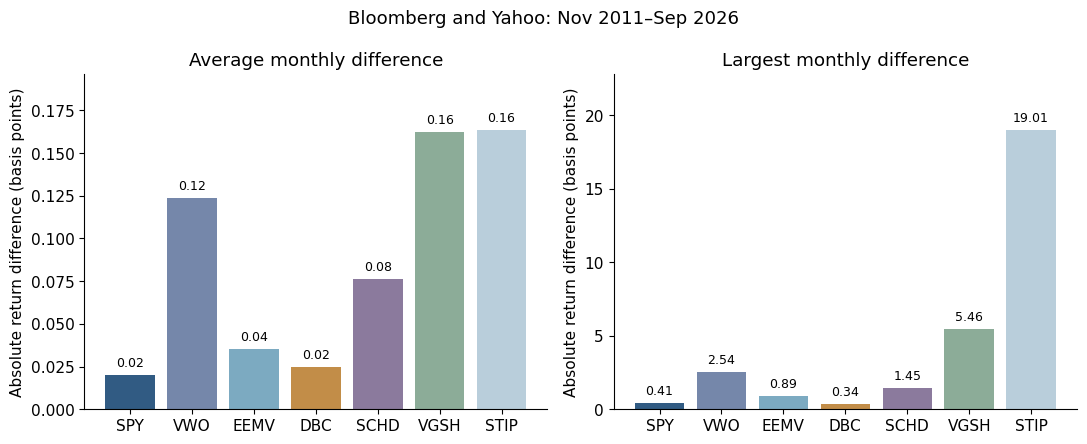

In [12]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for axis, (column, title) in zip(axes, [
    ("mean_absolute_return_difference", "Average monthly difference"),
    ("max_absolute_return_difference", "Largest monthly difference"),
]):
    bars = axis.bar(source_comparison.index, source_comparison[column] * 10_000,
                    color=[ASSET_COLORS[ticker] for ticker in source_comparison.index])
    axis.bar_label(bars, fmt="%.2f", padding=4, fontsize=9)
    axis.set(title=title, ylabel="Absolute return difference (basis points)")
    axis.set_ylim(0, source_comparison[column].max() * 10_000 * 1.2)
figure.suptitle(f"Bloomberg and Yahoo: {common_months[0]:%b %Y}–{common_months[-1]:%b %Y}", fontsize=13)
save_chart(figure, "data_source_differences")

## 3. How do the alternative limits affect historical performance?

Each allocation keeps its own target weights fixed over November 2016–September 2026, with monthly rebalancing. All cases use the same returns, risk-free proxy and cost of 10 basis points per dollar bought or sold, including the initial investment.

### Monthly calculation

We first measure the trades needed to restore the target weights after the previous month's drift. Both purchases and sales enter the traded fraction $T_t$

$$T_t=\sum_i\left|w_i-\widetilde{w}_{i,t}\right|$$

$$r_{p,t}^{net}=(1-cT_t)(1+w^\top r_t)-1$$

Here $c$ is the cost per dollar traded. The risk-free proxy uses the last DGS1MO yield available before the month starts, accrued over that month's calendar days

$$r_{f,t}=\frac{y_{t^-}}{100}\frac{D_t}{365}$$

$$\widehat{S}=\frac{12\operatorname{mean}(r_p^{net}-r_f)}{\sqrt{12}\operatorname{sd}(r_p^{net})}$$

These are retrospective comparisons: the weights use the current estimation window and the limits were considered after reviewing history. We use the results to describe sensitivity, rather than select the limits with the highest historical Sharpe. Exact weights are used here, so the baseline differs slightly from the rounded allocation in the main notebook.

In [13]:
treasury = pd.read_csv(DATA / "fred_dgs1mo.csv", parse_dates=["observation_date"])
treasury["DGS1MO"] = pd.to_numeric(treasury["DGS1MO"], errors="coerce")
treasury = treasury.dropna(subset=["DGS1MO"]).set_index("observation_date").sort_index()
risk_free_rows = []
for month in returns.index:
    first_day = month.replace(day=1)
    prior = treasury.loc[treasury.index < first_day, "DGS1MO"]
    if prior.empty:
        raise ValueError(f"No Treasury yield available before {first_day.date()}.")
    annual_yield_percent = float(prior.iloc[-1])
    monthly_proxy = annual_yield_percent / 100 * month.days_in_month / 365
    risk_free_rows.append([month, prior.index[-1], annual_yield_percent, monthly_proxy])
risk_free_table = pd.DataFrame(risk_free_rows, columns=[
    "month", "yield_observation_date", "annual_yield_percent", "monthly_rf_proxy"
]).set_index("month")
risk_free = risk_free_table["monthly_rf_proxy"]

In [14]:
def simulate_fixed_weights(weights, asset_returns, trading_cost=TRADING_COST):
    drifted_weights = np.zeros(len(weights))
    rows = []
    for month, observations in asset_returns.iterrows():
        traded_fraction = float(np.abs(weights - drifted_weights).sum())
        gross_return = float(weights @ observations.to_numpy())
        net_return = (1 - trading_cost * traded_fraction) * (1 + gross_return) - 1
        rows.append([month, gross_return, traded_fraction, net_return])
        drifted_weights = weights * (1 + observations.to_numpy()) / (1 + gross_return)
    return pd.DataFrame(rows, columns=["month", "gross_return", "traded_fraction", "net_return"]).set_index("month")


def performance_statistics(net_returns):
    observations = net_returns.to_numpy()
    # Include initial wealth so an immediate first-month loss counts as drawdown.
    wealth = np.cumprod(np.r_[1.0, 1 + observations])
    drawdown = wealth / np.maximum.accumulate(wealth) - 1
    volatility = observations.std(ddof=1) * np.sqrt(12)
    excess_returns = net_returns - risk_free.reindex(net_returns.index)
    assert excess_returns.notna().all()
    return pd.Series({
        "months": len(observations),
        "cagr": wealth[-1]**(12 / len(observations)) - 1,
        "volatility": volatility,
        "sharpe": excess_returns.mean() * 12 / volatility,
        "max_month_end_drawdown": drawdown.min(),
        "historical_monthly_95pct_var": -np.quantile(observations, 0.05, method="linear"),
        "terminal_value_usd": CAPITAL * wealth[-1],
    })

In [15]:
study_evaluation = returns.loc[BACKTEST_START:, ASSETS]
sensitivity_performance = pd.DataFrame({
    label: performance_statistics(simulate_fixed_weights(weights, study_evaluation)["net_return"])
    for label, weights in sensitivity_weights.items()
}).T
sensitivity_performance.to_csv(STUDIES / "constraint_backtest_context.csv")

display(sensitivity_performance.loc[selected, ["cagr", "volatility", "sharpe", "max_month_end_drawdown"]]
        .rename(index=readable_scenario, columns={"cagr": "Annual return", "volatility": "Realized volatility",
            "sharpe": "Sharpe", "max_month_end_drawdown": "Maximum month-end drawdown"})
        .style.format({"Annual return": "{:.2%}", "Realized volatility": "{:.2%}", "Sharpe": "{:.3f}",
                       "Maximum month-end drawdown": "{:.2%}"}))

,Annual return,Realized volatility,Sharpe,Maximum month-end drawdown
ETF risk cap: 35.0%,8.96%,8.61%,0.758,-16.26%
ETF risk cap: 37.5%,9.00%,8.61%,0.763,-16.24%
Baseline,9.04%,8.60%,0.768,-16.19%
ETF risk cap: 42.5%,9.07%,8.59%,0.772,-16.11%
ETF risk cap: 45.0%,9.13%,8.55%,0.782,-15.80%


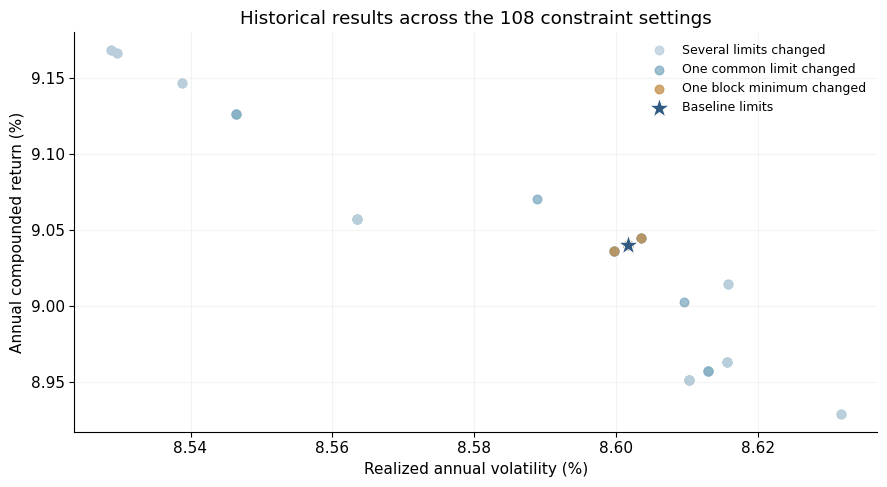

In [16]:
figure, axis = plt.subplots(figsize=(9, 5))
for kind, label, color in [("joint", "Several limits changed", "#b9cedb"),
                            ("one_limit", "One common limit changed", "#7caac1"),
                            ("individual_floor", "One block minimum changed", "#c28d48")]:
    scenarios = sensitivity.index[sensitivity["kind"] == kind]
    points = sensitivity_performance.loc[scenarios]
    axis.scatter(points["volatility"] * 100, points["cagr"] * 100, color=color,
                  s=38, alpha=0.75, label=label)
baseline_result = sensitivity_performance.loc["Baseline"]
axis.scatter(baseline_result["volatility"] * 100, baseline_result["cagr"] * 100,
             marker="*", s=230, color="#315b83", edgecolor="white", linewidth=0.7, zorder=5,
             label="Baseline limits")
axis.set(title="Historical results across the 108 constraint settings", xlabel="Realized annual volatility (%)",
         ylabel="Annual compounded return (%)")
axis.grid(alpha=0.15)
axis.legend(frameon=False, fontsize=9)
save_chart(figure, "constraint_backtest_comparison")

Every specification targets 8% volatility in the estimation window. Realized volatility over the historical comparison period can differ. The points are related allocations on the same return history, not independent performance observations.

## 4. What happens with an earlier estimation window?

We repeat the allocation exercise at two earlier starting points, using only the preceding 60 monthly returns for each fit. The resulting targets stay fixed during the following evaluation period, with monthly rebalancing.

| Test | Estimate weights using | Evaluate using |
|:--|:--|:--|
| First | November 2011–October 2016 | November 2016–September 2026 |
| Second | November 2016–October 2021 | November 2021–September 2026 |

The six selected ETFs are used in both tests. MVO tries an 8% volatility target, then 7.5% and 7% only if the optimizer cannot find a feasible solution. Equal weight and risk parity are not scaled to that target. The reported target applies only to MVO.

The fitting windows exclude their later evaluation returns. However, the ETF universe and rules were chosen after reviewing history, so these tests are not untouched holdouts. The two evaluation periods also overlap.

In [17]:
def historical_parity(covariance):
    count = len(covariance)
    scaled = covariance / np.mean(np.diag(covariance))
    budgets = np.ones(count) / count
    solution = minimize(lambda x: 0.5 * x @ scaled @ x - budgets @ np.log(x),
                        np.ones(count), jac=lambda x: scaled @ x - budgets / x,
                        bounds=[(1e-10, None)] * count, method="L-BFGS-B",
                        options={"ftol": 1e-15, "gtol": 1e-10, "maxiter": 3000})
    weights = solution.x / solution.x.sum()
    assert np.max(abs(risk_shares(weights, covariance) - budgets)) < 1e-7
    return weights

historical_assets = ["SPY", "EEMV", "DBC", "VGSH", "SCHD", "STIP"]
historical_results = []
historical_weights = []
for first_test_month in ["2016-11-30", "2021-11-30"]:
    start = pd.Timestamp(first_test_month)
    sample = returns.loc[returns.index < start, historical_assets].tail(60)
    assert len(sample) == 60 and sample.index[-1] < start
    trained_weights = None
    for target in [0.08, 0.075, 0.07]:
        try:
            trained_weights, diagnostics = optimize_weights(sample, POLICY, target=target)
            break
        except RuntimeError:
            continue
    if trained_weights is None:
        raise RuntimeError("No verified historical fit in the volatility band.")
    sample_covariance = sample.cov().to_numpy() * 12
    alternatives = {"Trained MVO": trained_weights,
                    "Equal weight": np.ones(6) / 6,
                    "Trained risk parity": historical_parity(sample_covariance)}
    for name, weights in alternatives.items():
        net = simulate_fixed_weights(weights, returns.loc[start:, historical_assets])["net_return"]
        row = performance_statistics(net).to_dict()
        row.update(test_start=first_test_month, portfolio=name, fit_first=str(sample.index[0].date()),
                   fit_last=str(sample.index[-1].date()), selected_mvo_volatility_target=target)
        historical_results.append(row)
        historical_weights.append({"test_start": first_test_month, "portfolio": name,
                                   **dict(zip(historical_assets, weights))})
historical_summary = pd.DataFrame(historical_results)
historical_summary.to_csv(STUDIES / "historical_fit_summary.csv", index=False)
pd.DataFrame(historical_weights).to_csv(STUDIES / "historical_fit_weights.csv", index=False)

historical_display = historical_summary[["test_start", "portfolio", "selected_mvo_volatility_target",
                                        "cagr", "volatility", "sharpe"]].copy()
historical_display.loc[historical_display["portfolio"] != "Trained MVO", "selected_mvo_volatility_target"] = np.nan
display(historical_display.rename(columns={"test_start": "Evaluation starts", "portfolio": "Portfolio",
    "selected_mvo_volatility_target": "MVO fit target", "cagr": "Annual return",
    "volatility": "Realized volatility", "sharpe": "Sharpe"})
    .style.format({"MVO fit target": "{:.1%}", "Annual return": "{:.2%}",
                   "Realized volatility": "{:.2%}", "Sharpe": "{:.3f}"}, na_rep="—"))

,Evaluation starts,Portfolio,MVO fit target,Annual return,Realized volatility,Sharpe
0,2016-11-30,Trained MVO,8.0%,10.68%,10.24%,0.807
1,2016-11-30,Equal weight,—,8.49%,8.30%,0.731
2,2016-11-30,Trained risk parity,—,2.96%,2.06%,0.241
3,2021-11-30,Trained MVO,8.0%,7.60%,7.18%,0.520
4,2021-11-30,Equal weight,—,7.67%,7.80%,0.493
5,2021-11-30,Trained risk parity,—,2.74%,2.47%,-0.458


### How the estimated MVO weights change

These are the exact allocations estimated at each earlier starting point. They are separate historical portfolios, not changes to the main target allocation.

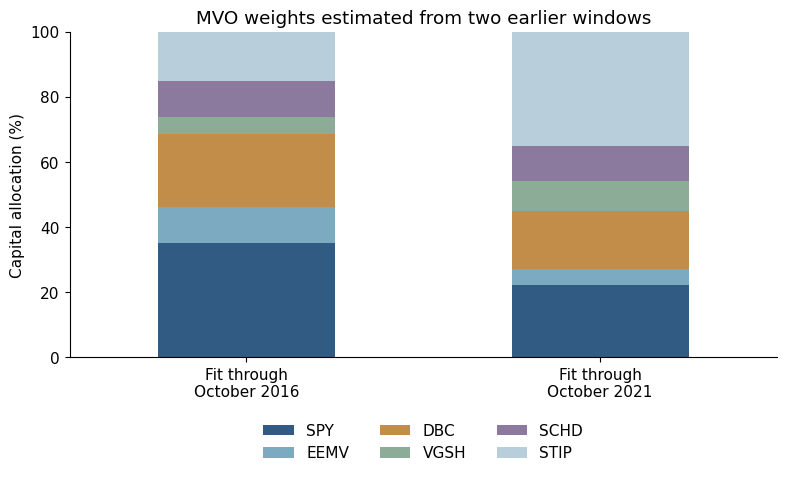

In [18]:
historical_weight_table = pd.DataFrame(historical_weights)
mvo_weights_by_window = historical_weight_table.loc[historical_weight_table["portfolio"] == "Trained MVO"]
mvo_weights_by_window = mvo_weights_by_window.set_index("test_start")[historical_assets]
mvo_weights_by_window.index = ["Fit through\nOctober 2016", "Fit through\nOctober 2021"]
figure, axis = plt.subplots(figsize=(8, 5))
(mvo_weights_by_window * 100).plot.bar(stacked=True, ax=axis, rot=0, width=0.5,
    color=[ASSET_COLORS[ticker] for ticker in historical_assets])
axis.set(title="MVO weights estimated from two earlier windows", ylabel="Capital allocation (%)",
         xlabel="", ylim=(0, 100))
axis.legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16))
save_chart(figure, "historical_fit_allocations")

### Compare the strategies within each period

The shaded strip is the 7–9% volatility budget. It provides context for realized volatility; it is not a guarantee that a portfolio remains inside the band after estimation.

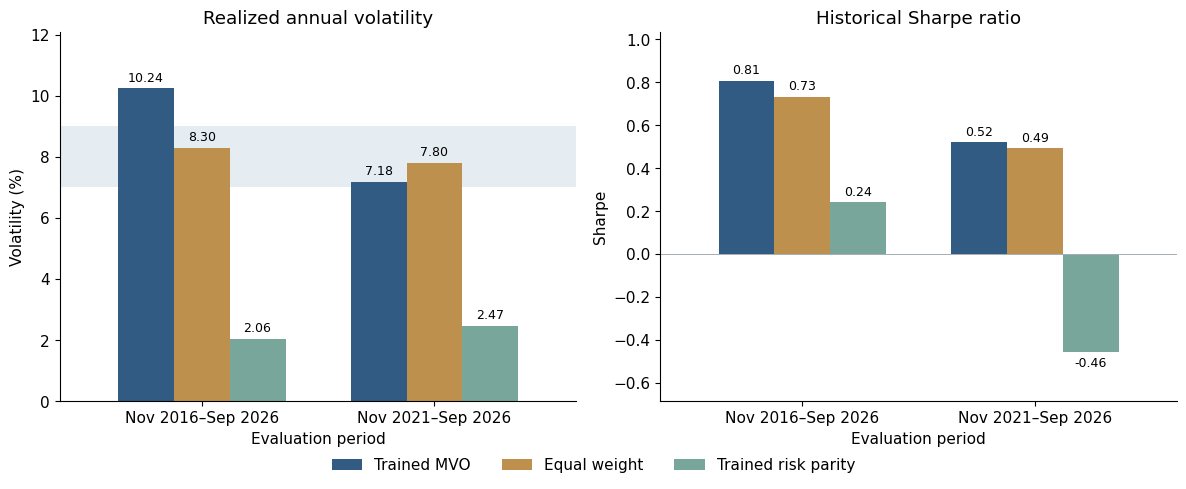

In [19]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4.7))
strategy_order = list(STRATEGY_COLORS)
window_labels = ["Nov 2016–Sep 2026", "Nov 2021–Sep 2026"]
for axis, metric, title in [(axes[0], "volatility", "Realized annual volatility"),
                             (axes[1], "sharpe", "Historical Sharpe ratio")]:
    table = historical_summary.pivot(index="test_start", columns="portfolio", values=metric)[strategy_order]
    if metric == "volatility":
        table = table * 100
        axis.axhspan(7, 9, facecolor="#e5edf3", zorder=0)
    table.index = window_labels
    table.plot.bar(ax=axis, width=0.72, rot=0, color=[STRATEGY_COLORS[name] for name in strategy_order], legend=False)
    for container in axis.containers:
        axis.bar_label(container, fmt="%.2f", padding=3, fontsize=9)
    axis.set(title=title, xlabel="Evaluation period", ylabel="Volatility (%)" if metric == "volatility" else "Sharpe")
    axis.margins(y=0.18)
    axis.axhline(0, color="#a5adb5", lw=0.7)
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(handles, labels, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.05))
save_chart(figure, "historical_fit_performance")

The estimation period changes the chosen weights and the subsequent results. An initial 8% volatility estimate does not guarantee 8% realized volatility. Differences between MVO and risk parity here also reflect their different risk levels.

## 5. How much do trading costs matter?

We keep the main notebook's rounded target weights fixed and repeat its monthly backtest at three cost assumptions: 0, 10 and 25 basis points per dollar traded. Initial investment is charged in each case. The 10-basis-point case is the main assumption.

For example, trading USD 1 million at 10 basis points costs USD 1,000. The same net-return formula from Section 3 is used in all cases.

In [20]:
main_weights = allocation["target_weight"].to_numpy()
cost_checks = pd.DataFrame({
    str(cost): performance_statistics(simulate_fixed_weights(main_weights, study_evaluation, cost)["net_return"])
    for cost in [0.0, 0.001, 0.0025]
}).T
cost_checks.index.name = "cost_per_dollar_traded"
cost_checks.to_csv(STUDIES / "trading_cost_sensitivity.csv")

cost_display = cost_checks[["cagr", "volatility", "sharpe"]].copy()
cost_display.index = ["0 bp", "10 bp — main assumption", "25 bp"]
display(cost_display.rename(columns={"cagr": "Annual return", "volatility": "Realized volatility", "sharpe": "Sharpe"})
        .style.format({"Annual return": "{:.2%}", "Realized volatility": "{:.2%}", "Sharpe": "{:.3f}"}))

,Annual return,Realized volatility,Sharpe
0 bp,9.08%,8.60%,0.772
10 bp — main assumption,9.04%,8.60%,0.768
25 bp,8.98%,8.60%,0.762


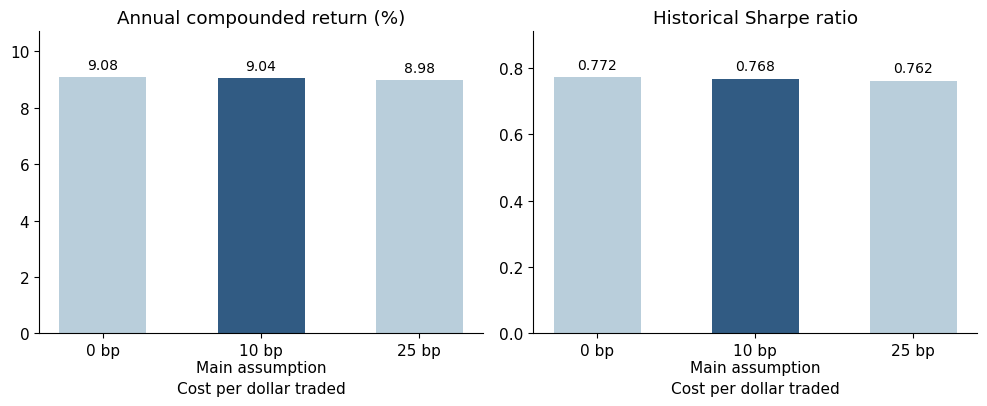

In [21]:
figure, axes = plt.subplots(1, 2, figsize=(10, 4.2))
cost_labels = ["0 bp", "10 bp\nMain assumption", "25 bp"]
for axis, column, title, scale in [(axes[0], "cagr", "Annual compounded return (%)", 100),
                                  (axes[1], "sharpe", "Historical Sharpe ratio", 1)]:
    bars = axis.bar(cost_labels, cost_checks[column] * scale,
                    color=["#b9cedb", "#315b83", "#b9cedb"], width=0.55)
    axis.bar_label(bars, fmt="%.3f" if column == "sharpe" else "%.2f", padding=4, fontsize=10)
    axis.set(title=title, xlabel="Cost per dollar traded")
    axis.set_ylim(0, cost_checks[column].max() * scale * 1.18)
save_chart(figure, "trading_cost_comparison")

## 6. How uncertain is the historical Sharpe ratio?

The reported Sharpe comes from one observed return history. To see how much it can vary, we use a block bootstrap:

1. Pair each net portfolio return with its month's risk-free proxy
2. Draw six-month blocks of these pairs, wrapping around the end of the sample
3. Join the blocks to make a sample with the original number of months
4. Calculate its annualized Sharpe and repeat 3,000 times

The middle 95% of the resulting estimates gives a conditional bootstrap interval. Blocks retain some of the dependence between neighbouring months.

**Interpretation:** this measures sampling uncertainty for the chosen strategy. It does not correct for choosing the ETFs, constraints or model after reviewing historical results, and it is not a forecast range for future Sharpe.

In [22]:
net = simulate_fixed_weights(main_weights, study_evaluation)["net_return"]
observations = net.to_numpy()
paired_risk_free = risk_free.reindex(net.index).to_numpy()
generator = np.random.default_rng(20261014)
block_length = 6
bootstrap_sharpes = []
for _ in range(3000):
    block_starts = generator.integers(0, len(net), size=(len(net) + block_length - 1) // block_length)
    indexes = np.concatenate([(start + np.arange(block_length)) % len(net) for start in block_starts])[:len(net)]
    sampled_returns = observations[indexes]
    sampled_risk_free = paired_risk_free[indexes]
    bootstrap_sharpes.append((sampled_returns - sampled_risk_free).mean()
                             / sampled_returns.std(ddof=1) * np.sqrt(12))
interval = pd.Series({"lower_2.5pct": np.quantile(bootstrap_sharpes, 0.025),
                      "upper_97.5pct": np.quantile(bootstrap_sharpes, 0.975)}, name="conditional_sharpe_interval")
interval.to_csv(STUDIES / "sharpe_bootstrap_interval.csv")

observed_sharpe = performance_statistics(net)["sharpe"]
display(pd.Series({"Historical Sharpe": observed_sharpe,
                   "Bootstrap lower bound (2.5%)": interval["lower_2.5pct"],
                   "Bootstrap upper bound (97.5%)": interval["upper_97.5pct"]}, name="Estimate")
        .to_frame().style.format("{:.3f}"))

,Estimate
Historical Sharpe,0.768
Bootstrap lower bound (2.5%),0.189
Bootstrap upper bound (97.5%),1.566


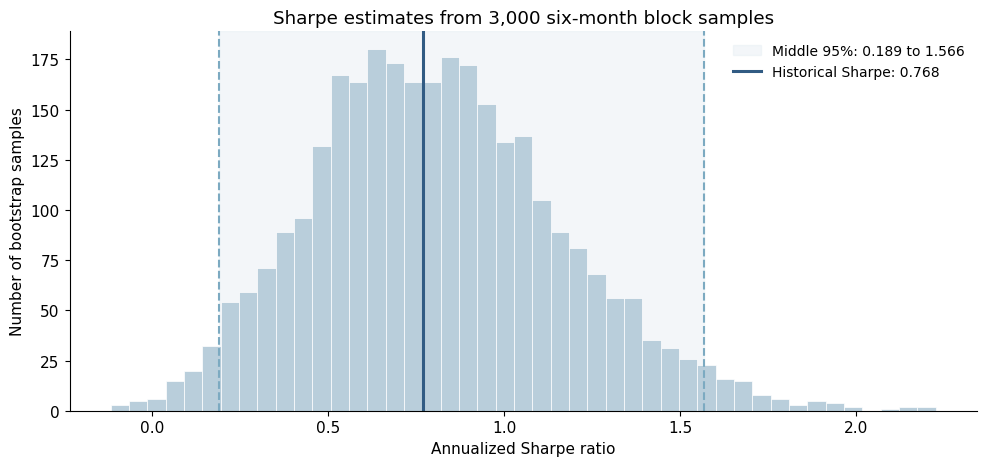

In [23]:
lower, upper = interval["lower_2.5pct"], interval["upper_97.5pct"]
figure, axis = plt.subplots(figsize=(10, 4.8))
axis.hist(bootstrap_sharpes, bins=45, color="#b9cedb", edgecolor="white", linewidth=0.5)
axis.axvspan(lower, upper, color="#e5edf3", alpha=0.45, zorder=0,
               label=f"Middle 95%: {lower:.3f} to {upper:.3f}")
axis.axvline(lower, color="#7caac1", linestyle="--", lw=1.5)
axis.axvline(upper, color="#7caac1", linestyle="--", lw=1.5)
axis.axvline(observed_sharpe, color="#315b83", lw=2.2,
               label=f"Historical Sharpe: {observed_sharpe:.3f}")
axis.set(title="Sharpe estimates from 3,000 six-month block samples",
         xlabel="Annualized Sharpe ratio", ylabel="Number of bootstrap samples")
axis.legend(frameon=False, fontsize=10)
save_chart(figure, "sharpe_uncertainty")

## 7. Efficient frontier under the same policy

We maximize the estimated annual arithmetic return with a volatility ceiling, keeping all other limits fixed. The grid runs from 4% to 12% in steps of 0.25 percentage point; the lowest-variance portfolio found is calculated separately. Risk budgets outside 7–9% are shown only to explain the trade-off, not as challenge recommendations.

The implementation uses the same risk-share formulas as the main optimizer. It changes the exact volatility equality to an upper bound for the frontier. In the return-input study, the original exact 8% target is retained.

Feasibility is checked independently after each solve. Both random seeds must find solutions with matching objectives. Failure to find a solution is recorded as a search outcome, not proof of mathematical infeasibility. The nonlinear risk-share constraints mean global optimality is not established.

In [24]:
held_assets = [ticker for ticker in ["SPY", "EEMV", "DBC", "VGSH", "SCHD", "STIP"]
               if allocation.loc[ticker, "target_weight"] > 1e-8]
held_covariance = annual_covariance.loc[held_assets, held_assets].to_numpy()
benchmark_weights = {
    "Constrained MVO": allocation.loc[held_assets, "target_weight"].to_numpy(),
    "Equal weight": np.ones(len(held_assets)) / len(held_assets),
    "Risk parity": historical_parity(held_covariance),
}
evaluation = returns.loc[BACKTEST_START:, held_assets]
backtest_returns = pd.DataFrame({name: simulate_fixed_weights(weights, evaluation)["net_return"]
                                 for name, weights in benchmark_weights.items()})
ROBUST_OUTPUT = STUDIES

In [25]:
def solve_study_weights(mean_inputs, covariance, *, ceiling=None, exact_target=None,
                        minimum_variance=False, warm_starts=(), seeds=(27, 83), random_starts=28):
    means = np.asarray(mean_inputs)
    count = len(means)
    equity_mask = np.array([a in {"SPY", "VWO", "EEMV", "SCHD"} for a in ASSETS], dtype=float)
    constraints = [
        {"type": "eq", "fun": lambda w: w.sum() - 1, "jac": lambda w: np.ones(count)},
        {"type": "ineq", "fun": lambda w: POLICY["risk_cap"] - risk_shares(w, covariance),
         "jac": lambda w: -risk_share_gradient(w, covariance)},
        {"type": "ineq", "fun": lambda w: POLICY["equity_risk_cap"] - equity_mask @ risk_shares(w, covariance),
         "jac": lambda w: -equity_mask @ risk_share_gradient(w, covariance)},
    ]
    if ceiling is not None:
        constraints.append({"type": "ineq", "fun": lambda w: 1 - (w @ covariance @ w) / ceiling**2,
                            "jac": lambda w: -2 * covariance @ w / ceiling**2})
    if exact_target is not None:
        constraints.append({"type": "eq", "fun": lambda w: (w @ covariance @ w) / exact_target**2 - 1,
                            "jac": lambda w: 2 * covariance @ w / exact_target**2})
    for group, tickers in {**GROUPS, "bonds": ["VGSH", "STIP"]}.items():
        mask = np.array([a in tickers for a in ASSETS], dtype=float)
        floor = POLICY["bond_floor"] if group == "bonds" else POLICY["building_block_floor"]
        constraints.append({"type": "ineq", "fun": lambda w, m=mask, f=floor: m @ w - f,
                            "jac": lambda w, m=mask: m})
    if minimum_variance:
        objective = lambda w: (w @ covariance @ w) / 0.01
        gradient = lambda w: 2 * covariance @ w / 0.01
    else:
        objective = lambda w: -means @ w
        gradient = lambda w: -means
    all_solutions = []
    seed_objectives = []
    for seed in seeds:
        generator = np.random.default_rng(seed)
        starts = [*warm_starts, np.ones(count) / count,
                  *generator.dirichlet(np.ones(count), random_starts)]
        feasible_solutions = []
        for initial in starts:
            solution = minimize(objective, initial, jac=gradient, method="SLSQP",
                                bounds=[(0, POLICY["capital_cap"])] * count, constraints=constraints,
                                options={"ftol": 1e-11, "maxiter": 500})
            weights = solution.x
            volatility = portfolio_volatility(weights, covariance)
            feasible = (solution.success and abs(weights.sum() - 1) < 1e-7
                        and policy_margins(weights, covariance, ASSETS, POLICY).min() >= -1e-7
                        and (ceiling is None or volatility <= ceiling + 1e-7)
                        and (exact_target is None or abs(volatility - exact_target) < 1e-7))
            if feasible:
                feasible_solutions.append(solution)
        seed_objectives.append(min((s.fun for s in feasible_solutions), default=np.nan))
        all_solutions.extend(feasible_solutions)
    if not all_solutions:
        raise RuntimeError("No feasible study solution found at this risk level.")
    if not np.isfinite(seed_objectives).all() or np.ptp(seed_objectives) > 1e-7:
        raise RuntimeError("Study solutions do not agree across the two seeds.")
    best = min(all_solutions, key=lambda solution: solution.fun)
    return best.x, float(np.ptp(seed_objectives))

In [26]:
study_covariance = annual_covariance.to_numpy()
study_means = annual_mean.to_numpy()
minimum_risk_weights, minimum_risk_gap = solve_study_weights(
    study_means, study_covariance, minimum_variance=True, warm_starts=(exact_weights,))
minimum_risk_found = portfolio_volatility(minimum_risk_weights, study_covariance)
frontier_rows = []
previous_weights = minimum_risk_weights
pd.DataFrame({"weight": minimum_risk_weights,
              "risk_share": risk_shares(minimum_risk_weights, study_covariance)}, index=ASSETS).to_csv(
                  ROBUST_OUTPUT / "minimum_risk_portfolio.csv", index_label="ticker")
for risk_ceiling in np.round(np.arange(0.04, 0.12001, 0.0025), 6):
    try:
        weights, seed_gap = solve_study_weights(study_means, study_covariance, ceiling=risk_ceiling,
            warm_starts=(minimum_risk_weights, previous_weights, exact_weights))
        previous_weights = weights
        frontier_rows.append({"volatility_ceiling": risk_ceiling, "status": "solution_found",
            "estimated_volatility": portfolio_volatility(weights, study_covariance),
            "estimated_return": float(study_means @ weights), "seed_objective_gap": seed_gap,
            **dict(zip(ASSETS, weights))})
    except RuntimeError as error:
        frontier_rows.append({"volatility_ceiling": risk_ceiling, "status": str(error)})
frontier = pd.DataFrame(frontier_rows)
frontier.to_csv(ROBUST_OUTPUT / "efficient_frontier.csv", index=False)
frontier_key = frontier.loc[np.isclose(frontier["volatility_ceiling"].to_numpy()[:, None],
                                      np.array([0.07, 0.075, 0.08, 0.085, 0.09])).any(axis=1)]
assert (frontier_key["status"] == "solution_found").all()
frontier_at_eight = frontier_key.loc[np.isclose(frontier_key["volatility_ceiling"], 0.08)].iloc[0]
assert abs(frontier_at_eight["estimated_return"] - float(study_means @ exact_weights)) < 1e-7
display(frontier_key[["volatility_ceiling", "estimated_volatility", "estimated_return"]]
    .rename(columns={"volatility_ceiling": "Risk ceiling", "estimated_volatility": "Estimated volatility",
                     "estimated_return": "Estimated annual return"}).set_index("Risk ceiling")
    .style.format("{:.2%}").format_index("{:.1%}"))

,Estimated volatility,Estimated annual return
Risk ceiling,,
7.0%,7.00%,8.32%
7.5%,7.50%,8.80%
8.0%,8.00%,9.28%
8.5%,8.50%,9.76%
9.0%,9.00%,10.23%


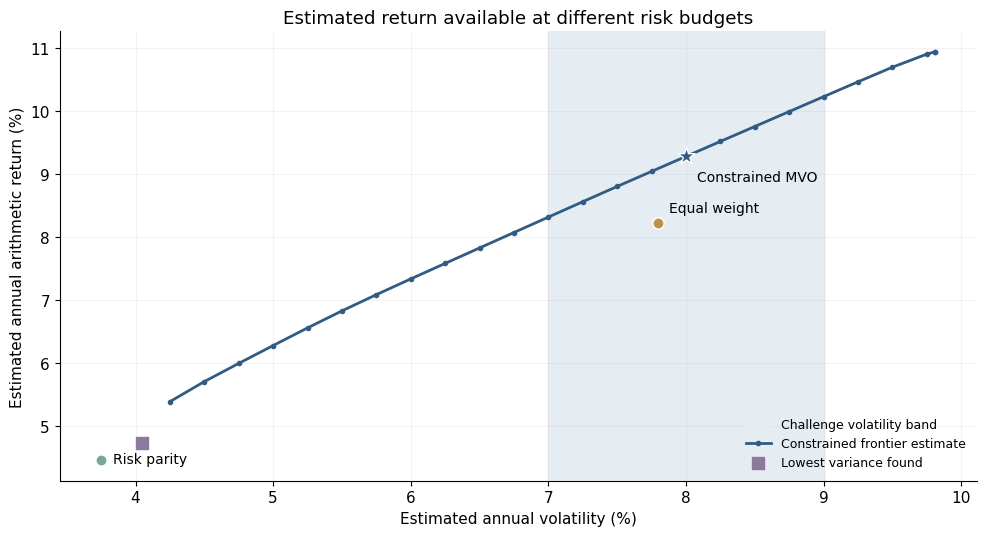

In [27]:
successful_frontier = frontier.loc[frontier["status"] == "solution_found"].copy()
successful_frontier = successful_frontier.sort_values(["estimated_volatility", "estimated_return"])
frontier_curve = successful_frontier.drop_duplicates("estimated_return", keep="first")
figure, axis = plt.subplots(figsize=(10, 5.5))
axis.axvspan(7, 9, color="#e5edf3", label="Challenge volatility band")
axis.plot(frontier_curve["estimated_volatility"] * 100, frontier_curve["estimated_return"] * 100,
          color="#315b83", lw=2, marker=".", label="Constrained frontier estimate")
axis.scatter(minimum_risk_found * 100, float(study_means @ minimum_risk_weights) * 100,
             marker="s", s=65, color="#8b7a9d", zorder=4, label="Lowest variance found")
for name, weights in benchmark_weights.items():
    full_weights = pd.Series(weights, index=held_assets).reindex(ASSETS, fill_value=0).to_numpy()
    point_volatility = portfolio_volatility(full_weights, study_covariance) * 100
    point_return = float(study_means @ full_weights) * 100
    color = {"Constrained MVO": "#315b83", "Equal weight": "#bd904d", "Risk parity": "#78a69b"}[name]
    axis.scatter(point_volatility, point_return, marker="*" if name == "Constrained MVO" else "o",
                  s=170 if name == "Constrained MVO" else 65, color=color, edgecolor="white", zorder=5)
    offset = (8, -2) if name == "Risk parity" else ((8, -18) if name == "Constrained MVO" else (8, 8))
    axis.annotate(name, (point_volatility, point_return), xytext=offset, textcoords="offset points", fontsize=10)
axis.set(title="Estimated return available at different risk budgets", xlabel="Estimated annual volatility (%)",
         ylabel="Estimated annual arithmetic return (%)")
axis.grid(alpha=0.15)
axis.legend(frameon=False, fontsize=9, loc="lower right")
save_chart(figure, "efficient_frontier")

### Frontier weights

These are exact solutions at the five risk ceilings inside the challenge band. The vertical axis in the chart uses the original fitting-window mean inputs. Reference portfolios do not necessarily satisfy the MVO limits.

In [28]:
display(frontier_key.set_index("volatility_ceiling")[[*ASSETS, "estimated_volatility", "estimated_return"]]
        .rename(columns={"estimated_volatility": "Estimated volatility", "estimated_return": "Estimated return"})
        .style.format("{:.2%}").format_index("{:.1%}"))

,SPY,VWO,EEMV,DBC,SCHD,VGSH,STIP,Estimated volatility,Estimated return
volatility_ceiling,,,,,,,,,
7.0%,22.86%,0.00%,8.38%,23.79%,0.96%,9.01%,35.00%,7.00%,8.32%
7.5%,24.49%,0.00%,8.55%,25.32%,2.20%,5.00%,34.45%,7.50%,8.80%
8.0%,26.08%,0.00%,9.65%,26.96%,3.28%,5.00%,29.03%,8.00%,9.28%
8.5%,27.69%,0.00%,10.73%,28.60%,4.31%,5.00%,23.66%,8.50%,9.76%
9.0%,29.32%,0.00%,11.79%,30.25%,5.30%,5.00%,18.34%,9.00%,10.23%


## 8. Do small changes to expected returns change the weights?

The previous constraint study changed the limits. Here we change the estimated returns, keeping the covariance matrix, ETF universe, policy and exact 8% volatility target fixed.

We specify the tests before inspecting their results:

| Test | Change |
|:--|:--|
| One ETF at a time | Add or subtract 1 and 2 percentage points from its annual mean |
| Larger commodity adjustment | Reduce DBC's annual mean by 4 percentage points |
| Within-group shrinkage | Move means 25%, 50% and 75% toward their group's average |

These are uncertainty scenarios, not forecasts. For shrinkage, SPY/SCHD form the US group, VWO/EEMV the emerging-market group and VGSH/STIP the bond group. DBC has no peer in this universe, so its mean is unchanged in that test. This only reduces differences within each group; it does not establish the correct return for any asset class.

$$\mu_i^{shock}=\widehat\mu_i+\delta_i$$

$$\mu_i^{shrink}=(1-\lambda)\widehat\mu_i+\lambda\overline\mu_{group(i)}$$

Multiplying every mean by the same positive factor would leave the return-maximizing weights unchanged, so it would not be an informative robustness test here. Capital reassigned is measured against the exact baseline, before rounding. Two seeds must find feasible solutions with matching objectives.

In [29]:
mean_scenarios = []
for ticker in ASSETS:
    for change in [-0.02, -0.01, 0.01, 0.02]:
        altered = annual_mean.copy()
        altered[ticker] += change
        mean_scenarios.append((f"{ticker} {change * 100:+.0f} pp", "one_etf", ticker, change, altered))
altered = annual_mean.copy()
altered["DBC"] -= 0.04
mean_scenarios.append(("DBC -4 pp", "larger_commodity_change", "DBC", -0.04, altered))
group_prior = annual_mean.copy()
for tickers in [["SPY", "SCHD"], ["VWO", "EEMV"], ["VGSH", "STIP"]]:
    group_prior.loc[tickers] = annual_mean.loc[tickers].mean()
for strength in [0.25, 0.50, 0.75]:
    altered = (1 - strength) * annual_mean + strength * group_prior
    mean_scenarios.append((f"Within-group shrinkage {strength:.0%}", "shrinkage", "groups", strength, altered))
assert len(mean_scenarios) == 32
mean_rows = []
input_rows = []
for label, kind, ticker, change, altered in mean_scenarios:
    weights, seed_gap = solve_study_weights(altered.to_numpy(), study_covariance,
        exact_target=TARGET_VOLATILITY, warm_starts=(exact_weights,))
    mean_rows.append({"scenario": label, "kind": kind, "changed_input": ticker, "input_change": change,
        "capital_reassigned_pct": float(abs(weights - exact_weights).sum() / 2 * 100),
        "max_weight_change_pp": float(abs(weights - exact_weights).max() * 100),
        "estimated_volatility": portfolio_volatility(weights, study_covariance),
        "return_under_changed_inputs": float(altered.to_numpy() @ weights),
        "return_under_original_inputs": float(study_means @ weights), "seed_objective_gap": seed_gap,
        **dict(zip(ASSETS, weights))})
    input_rows.append({"scenario": label, **altered.to_dict()})
mean_sensitivity = pd.DataFrame(mean_rows).set_index("scenario")
mean_sensitivity.to_csv(STUDIES / "mean_input_sensitivity.csv")
pd.DataFrame(input_rows).set_index("scenario").to_csv(STUDIES / "mean_input_scenarios.csv")
display(mean_sensitivity[[*ASSETS, "capital_reassigned_pct"]]
    .rename(columns={"capital_reassigned_pct": "Capital moved (%)"})
    .style.format({**{a: "{:.2%}" for a in ASSETS}, "Capital moved (%)": "{:.2f}"}))

,SPY,VWO,EEMV,DBC,SCHD,VGSH,STIP,Capital moved (%)
scenario,,,,,,,,
SPY -2 pp,26.07%,0.00%,10.26%,27.01%,2.91%,5.00%,28.76%,0.65
SPY -1 pp,26.08%,0.00%,9.98%,26.98%,3.08%,5.00%,28.88%,0.35
SPY +1 pp,26.09%,0.00%,9.27%,26.92%,3.51%,5.00%,29.20%,0.41
SPY +2 pp,26.11%,0.00%,8.81%,26.89%,3.78%,5.00%,29.42%,0.91
VWO -2 pp,26.08%,0.00%,9.65%,26.96%,3.28%,5.00%,29.03%,0.00
VWO -1 pp,26.08%,0.00%,9.65%,26.96%,3.28%,5.00%,29.03%,0.00
VWO +1 pp,26.28%,8.99%,0.00%,26.79%,1.56%,5.00%,31.38%,11.54
VWO +2 pp,26.30%,10.68%,0.00%,26.93%,0.00%,5.00%,31.09%,12.96
EEMV -2 pp,26.31%,5.00%,0.00%,26.52%,4.82%,5.00%,32.35%,10.09


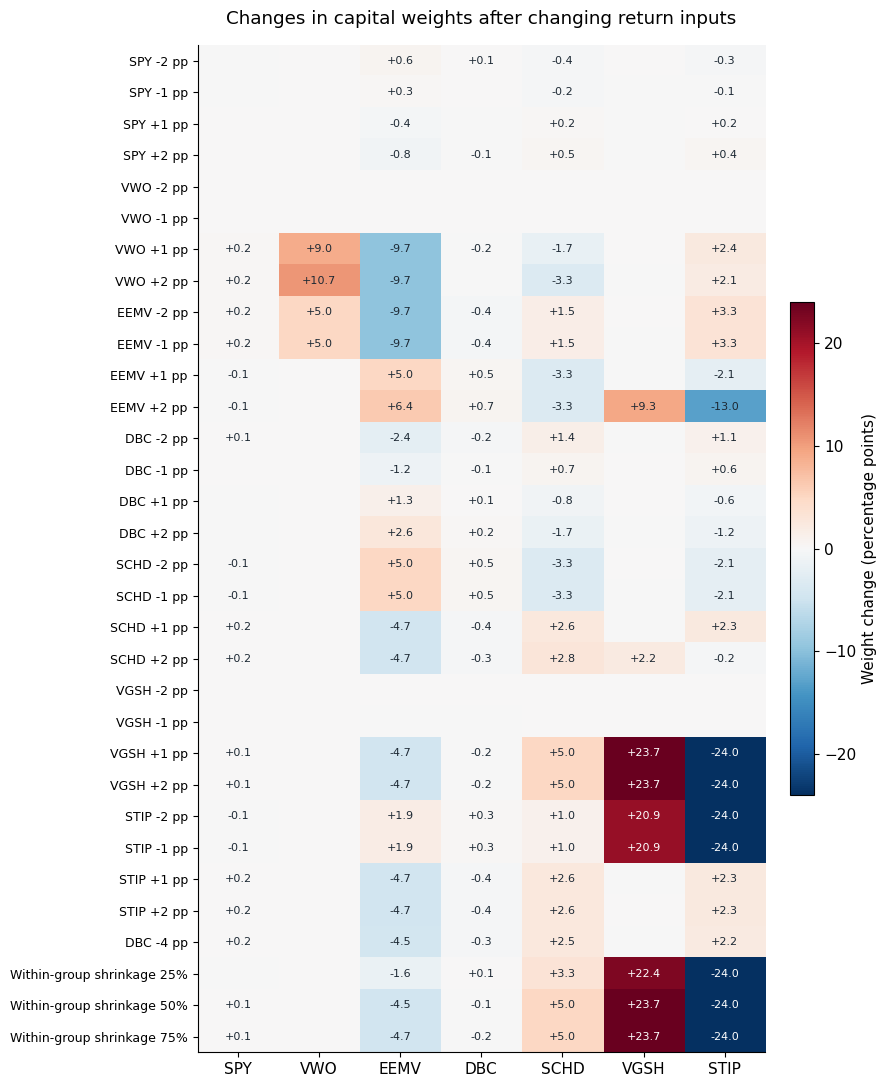

The largest capital reassignment among the ±1/±2 percentage-point single-ETF tests is **28.84%**, for **VGSH +1 pp**. Lowering DBC's annual mean by 2 points moves **2.56%** of capital; lowering it by 4 points moves **4.85%**. These comparisons show sensitivity within the chosen scenarios, not a probability that the original estimates are correct.

In [30]:
weight_changes = (mean_sensitivity[ASSETS] - exact_weights) * 100
limit = float(abs(weight_changes.to_numpy()).max())
figure, axis = plt.subplots(figsize=(9, 11))
image = axis.imshow(weight_changes, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
axis.set_xticks(range(len(ASSETS)), ASSETS)
axis.set_yticks(range(len(weight_changes)), weight_changes.index, fontsize=9)
axis.set_title("Changes in capital weights after changing return inputs", pad=15)
for i in range(len(weight_changes)):
    for j in range(len(ASSETS)):
        value = weight_changes.iloc[i, j]
        if abs(value) >= 0.05:
            axis.text(j, i, f"{value:+.1f}", ha="center", va="center", fontsize=8,
                      color="white" if abs(value) > limit * 0.55 else "#1c2833")
figure.colorbar(image, ax=axis, label="Weight change (percentage points)", fraction=0.04, pad=0.04)
save_chart(figure, "mean_input_sensitivity")
single_input = mean_sensitivity.loc[mean_sensitivity["kind"] == "one_etf"]
largest_change = single_input["capital_reassigned_pct"].idxmax()
commodity_cases = mean_sensitivity.loc[["DBC -2 pp", "DBC -4 pp"], "capital_reassigned_pct"]
display(Markdown(
    f"The largest capital reassignment among the ±1/±2 percentage-point single-ETF tests is "
    f"**{single_input.loc[largest_change, 'capital_reassigned_pct']:.2f}%**, for **{largest_change}**. "
    f"Lowering DBC's annual mean by 2 points moves **{commodity_cases.iloc[0]:.2f}%** of capital; "
    f"lowering it by 4 points moves **{commodity_cases.iloc[1]:.2f}%**. "
    "These comparisons show sensitivity within the chosen scenarios, not a probability that the original estimates are correct."
))

### What this means for the allocation

The bond split is sensitive to small differences in estimated returns. Raising VGSH's annual mean by one percentage point moves much of the STIP allocation into VGSH. The emerging-market choice can also switch between EEMV and VWO. DBC's capital weight changes less in the tested mean shocks, partly because the risk cap constrains its allocation.

We retain the selected portfolio for this analysis, but these findings do not support calling every weight robust. For a future allocation review, a less return-sensitive bond split and explicit within-group allocation rules are worth comparing. This study has not established that any replacement rule performs better.

## 9. Historical and hypothetical stress scenarios

The historical windows are 2018 Q4, February–March 2020 and calendar 2022. Current targets are rebalanced monthly with no fees, so the scenarios isolate market returns. All three portfolios start at USD 100 million for each episode. This is a retrospective replay, not evidence that these holdings were selected before the events.

The hypothetical scenarios specify simultaneous ETF returns directly. They illustrate a growth shock, a commodity reversal and a mix of falling equity prices, falling bond prices and rising commodities. The numbers are chosen assumptions, with no estimated probabilities or assigned horizon; they are not a factor model or a forecast.

For a hypothetical shock, each ETF contributes $w_i s_i$. For a historical multi-month episode, the contribution is linked through the portfolio's changing value

$$C_i=\sum_t V_{t-1}w_i r_{i,t}$$

Here $V$ starts at one. The ETF contributions sum to the total portfolio return. They are not obtained by multiplying the ETF's cumulative return by its initial weight, because the portfolio is rebalanced monthly.

In [31]:
historical_episodes = {
    "2018 Q4": ("2018-10", "2018-12"),
    "2020 February–March": ("2020-02", "2020-03"),
    "2022 calendar year": ("2022-01", "2022-12"),
}
hypothetical_shocks = pd.DataFrame({
    "Growth shock": {"SPY": -0.20, "VWO": -0.25, "EEMV": -0.18, "DBC": -0.15,
                     "SCHD": -0.20, "VGSH": 0.01, "STIP": -0.01},
    "Commodity reversal": {"SPY": -0.08, "VWO": -0.10, "EEMV": -0.08, "DBC": -0.30,
                           "SCHD": -0.08, "VGSH": 0.005, "STIP": -0.03},
    "Inflation and rates shock": {"SPY": -0.15, "VWO": -0.12, "EEMV": -0.10, "DBC": 0.15,
                                 "SCHD": -0.12, "VGSH": -0.02, "STIP": -0.04},
}).reindex(ASSETS)
hypothetical_shocks.to_csv(ROBUST_OUTPUT / "stress_scenario_assumptions.csv")
stress_rows = []
stress_component_rows = []
stress_path_rows = []
for portfolio, weights in benchmark_weights.items():
    full_weights = pd.Series(weights, index=held_assets).reindex(ASSETS, fill_value=0).to_numpy()
    for scenario, (first_month, last_month) in historical_episodes.items():
        episode = returns.loc[first_month:last_month, ASSETS]
        assert len(episode) > 0
        relative_value = 1.0
        path = [relative_value]
        contributions = np.zeros(len(ASSETS))
        stress_path_rows.append({"scenario": scenario, "portfolio": portfolio,
            "month": episode.index[0] - pd.offsets.MonthEnd(1), "value_usd": CAPITAL})
        for month, observations in episode.iterrows():
            # Linked contributions reconcile to the whole multi-month portfolio return.
            contributions += relative_value * full_weights * observations.to_numpy()
            relative_value *= 1 + float(full_weights @ observations.to_numpy())
            path.append(relative_value)
            stress_path_rows.append({"scenario": scenario, "portfolio": portfolio,
                "month": month, "value_usd": CAPITAL * relative_value})
        scenario_return = relative_value - 1
        assert abs(contributions.sum() - scenario_return) < 1e-12
        stress_rows.append({"scenario": scenario, "type": "historical", "portfolio": portfolio,
            "months": len(episode), "scenario_return": scenario_return,
            "pnl_usd": CAPITAL * scenario_return,
            "max_month_end_drawdown": float((np.array(path) / np.maximum.accumulate(path) - 1).min())})
        for i, ticker in enumerate(ASSETS):
            stress_component_rows.append({"scenario": scenario, "type": "historical", "portfolio": portfolio,
                "ticker": ticker, "weight": full_weights[i],
                "asset_scenario_return": float((1 + episode[ticker]).prod() - 1),
                "contribution_to_portfolio_return": contributions[i], "contribution_usd": CAPITAL * contributions[i]})
    for scenario in hypothetical_shocks:
        shocks = hypothetical_shocks[scenario].to_numpy()
        contributions = full_weights * shocks
        scenario_return = float(contributions.sum())
        stress_rows.append({"scenario": scenario, "type": "hypothetical", "portfolio": portfolio,
            "months": np.nan, "scenario_return": scenario_return, "pnl_usd": CAPITAL * scenario_return,
            "max_month_end_drawdown": np.nan})
        for i, ticker in enumerate(ASSETS):
            stress_component_rows.append({"scenario": scenario, "type": "hypothetical", "portfolio": portfolio,
                "ticker": ticker, "weight": full_weights[i], "asset_scenario_return": shocks[i],
                "contribution_to_portfolio_return": contributions[i], "contribution_usd": CAPITAL * contributions[i]})
stress_summary = pd.DataFrame(stress_rows)
stress_components = pd.DataFrame(stress_component_rows)
stress_paths = pd.DataFrame(stress_path_rows)
stress_summary.to_csv(ROBUST_OUTPUT / "stress_summary.csv", index=False)
stress_components.to_csv(ROBUST_OUTPUT / "stress_contributions.csv", index=False)
stress_paths.to_csv(ROBUST_OUTPUT / "historical_stress_paths.csv", index=False)
display(stress_summary.loc[stress_summary["portfolio"] == "Constrained MVO",
    ["scenario", "type", "scenario_return", "pnl_usd"]].set_index("scenario")
    .rename(columns={"type": "Scenario type", "scenario_return": "Portfolio return", "pnl_usd": "P&L on USD 100m"})
    .style.format({"Portfolio return": "{:.2%}", "P&L on USD 100m": "${:,.0f}"}))

,Scenario type,Portfolio return,P&L on USD 100m
scenario,,,
2018 Q4,historical,-9.35%,"$-9,345,540"
2020 February–March,historical,-13.82%,"$-13,824,590"
2022 calendar year,historical,-2.35%,"$-2,350,532"
Growth shock,hypothetical,-11.89%,"$-11,893,600"
Commodity reversal,hypothetical,-12.05%,"$-12,052,500"
Inflation and rates shock,hypothetical,-2.49%,"$-2,490,300"


### Hypothetical shock assumptions

Each cell is the assumed ETF return in one simultaneous scenario. All assumptions are saved in `stress_scenario_assumptions.csv`.

In [32]:
display(hypothetical_shocks.style.format("{:+.1%}"))

,Growth shock,Commodity reversal,Inflation and rates shock
SPY,-20.0%,-8.0%,-15.0%
VWO,-25.0%,-10.0%,-12.0%
EEMV,-18.0%,-8.0%,-10.0%
DBC,-15.0%,-30.0%,+15.0%
SCHD,-20.0%,-8.0%,-12.0%
VGSH,+1.0%,+0.5%,-2.0%
STIP,-1.0%,-3.0%,-4.0%


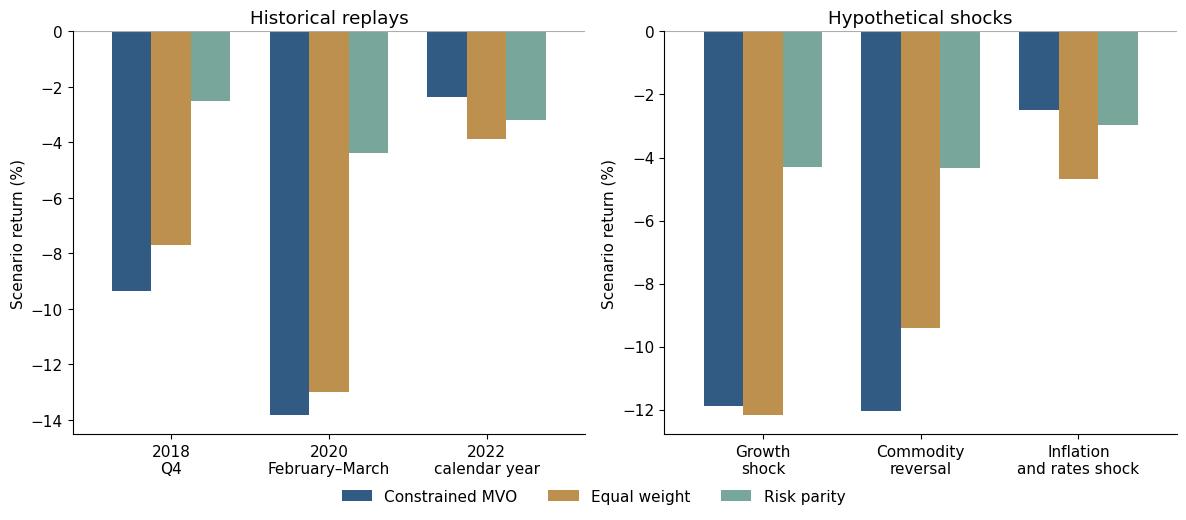

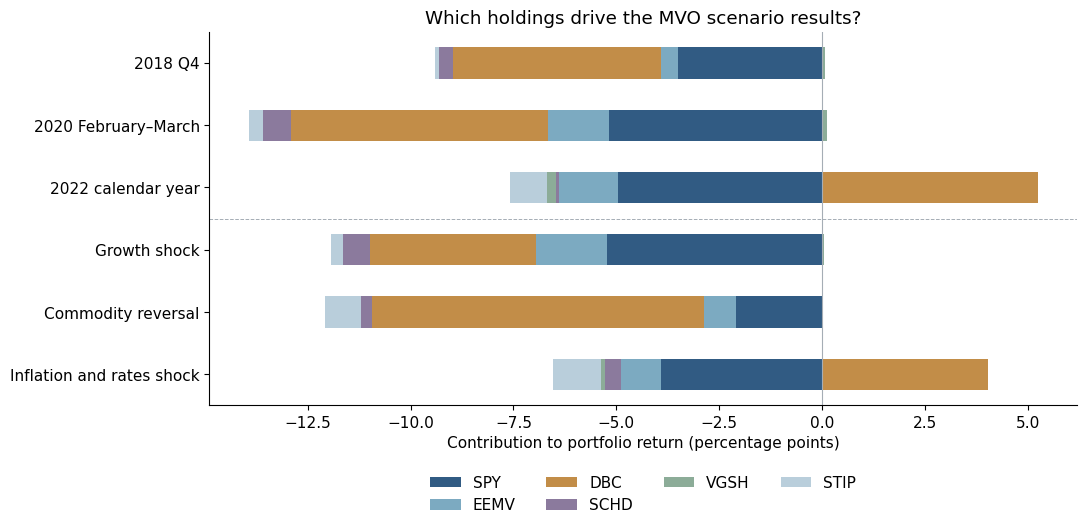

In [33]:
portfolio_order = ["Constrained MVO", "Equal weight", "Risk parity"]
portfolio_colors = ["#315b83", "#bd904d", "#78a69b"]
figure, axes = plt.subplots(1, 2, figsize=(12, 5))
for axis, kind, title in [(axes[0], "historical", "Historical replays"),
                           (axes[1], "hypothetical", "Hypothetical shocks")]:
    table = stress_summary.loc[stress_summary["type"] == kind].pivot(
        index="scenario", columns="portfolio", values="scenario_return")[portfolio_order]
    table = table.reindex(list(historical_episodes) if kind == "historical" else list(hypothetical_shocks))
    table.index = [label.replace(" ", "\n", 1) for label in table.index]
    (table * 100).plot.bar(ax=axis, color=portfolio_colors, rot=0, width=0.75, legend=False)
    axis.axhline(0, color="#a5adb5", lw=0.8)
    axis.set(title=title, ylabel="Scenario return (%)", xlabel="")
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(handles, labels, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.05))
save_chart(figure, "stress_comparison")

mvo_contributions = stress_components.loc[stress_components["portfolio"] == "Constrained MVO"]
contribution_table = mvo_contributions.pivot(index="scenario", columns="ticker",
                                           values="contribution_to_portfolio_return").reindex(
                                               [*historical_episodes, *hypothetical_shocks])[ASSETS]
contribution_assets = [a for a in ASSETS if contribution_table[a].abs().max() > 1e-8]
figure, axis = plt.subplots(figsize=(11, 5.5))
(contribution_table[contribution_assets] * 100).plot.barh(
    stacked=True, ax=axis, color=[ASSET_COLORS[a] for a in contribution_assets])
axis.axhline(2.5, color="#a5adb5", lw=0.7, linestyle="--")
axis.axvline(0, color="#a5adb5", lw=0.8)
axis.invert_yaxis()
axis.set(title="Which holdings drive the MVO scenario results?", xlabel="Contribution to portfolio return (percentage points)", ylabel="")
axis.legend(ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15))
save_chart(figure, "stress_contributions")

### Scenario calculations by holding

The following table shows MVO's linked contributions. Detailed contributions for all three portfolios and the historical monthly paths are saved as CSV files. Positive contributions offset losses; negative contributions increase them.

In [34]:
display(contribution_table.style.format("{:+.2%}"))

ticker,SPY,VWO,EEMV,DBC,SCHD,VGSH,STIP
scenario,,,,,,,
2018 Q4,-3.50%,+0.00%,-0.40%,-5.07%,-0.34%,+0.06%,-0.10%
2020 February–March,-5.18%,+0.00%,-1.48%,-6.26%,-0.68%,+0.11%,-0.34%
2022 calendar year,-4.96%,+0.00%,-1.42%,+5.24%,-0.09%,-0.20%,-0.91%
Growth shock,-5.22%,-0.00%,-1.74%,-4.04%,-0.66%,+0.05%,-0.29%
Commodity reversal,-2.09%,-0.00%,-0.77%,-8.09%,-0.26%,+0.03%,-0.87%
Inflation and rates shock,-3.91%,-0.00%,-0.97%,+4.04%,-0.39%,-0.10%,-1.16%


## 10. Expected shortfall

We use the same 119 net monthly returns as the main backtest. The empirical expected shortfall is the negative mean of the worst 5% of the empirical distribution. A fractional boundary observation makes the tail mass exactly 5%: five full returns plus 0.95 of the sixth return, divided by 5.95.

The historical VaR remains the linearly interpolated 5th percentile used in the existing backtest. VaR and ES use positive-loss notation. Both comparisons retain the portfolios' different risk levels; risk parity is not leveraged to match MVO.

There are few observations in the tail. The estimate excludes unobserved crises and does not correct historical selection bias. It should be read alongside the stress scenarios.

In [35]:
def historical_expected_shortfall(monthly_returns, tail_probability=0.05):
    if not 0 < tail_probability <= 1:
        raise ValueError("Tail probability must be between zero and one.")
    ordered = np.sort(np.asarray(monthly_returns, dtype=float))
    if len(ordered) == 0 or not np.isfinite(ordered).all():
        raise ValueError("Expected shortfall requires finite monthly returns.")
    tail_count = len(ordered) * tail_probability
    full_count = int(np.floor(tail_count))
    fractional_count = tail_count - full_count
    tail_total = ordered[:full_count].sum()
    if fractional_count > 0:
        tail_total += fractional_count * ordered[full_count]
    return float(-tail_total / tail_count)


tail_risk = pd.DataFrame({name: {
    "historical_monthly_95pct_var": -np.quantile(series, 0.05, method="linear"),
    "historical_monthly_95pct_es": historical_expected_shortfall(series),
    "worst_month": float(series.min()),
    "es_usd_on_initial_capital": CAPITAL * historical_expected_shortfall(series),
} for name, series in backtest_returns.items()}).T
tail_risk.to_csv(ROBUST_OUTPUT / "tail_risk.csv")
display(tail_risk.rename(columns={"historical_monthly_95pct_var": "Monthly 95% VaR",
    "historical_monthly_95pct_es": "Monthly 95% expected shortfall", "worst_month": "Worst month",
    "es_usd_on_initial_capital": "ES on USD 100m"})
    .style.format({"Monthly 95% VaR": "{:.2%}", "Monthly 95% expected shortfall": "{:.2%}",
                   "Worst month": "{:.2%}", "ES on USD 100m": "${:,.0f}"}))

,Monthly 95% VaR,Monthly 95% expected shortfall,Worst month,ES on USD 100m
Constrained MVO,3.68%,5.67%,-9.87%,"$5,668,350"
Equal weight,3.55%,5.44%,-9.00%,"$5,440,386"
Risk parity,1.21%,2.25%,-3.32%,"$2,254,730"


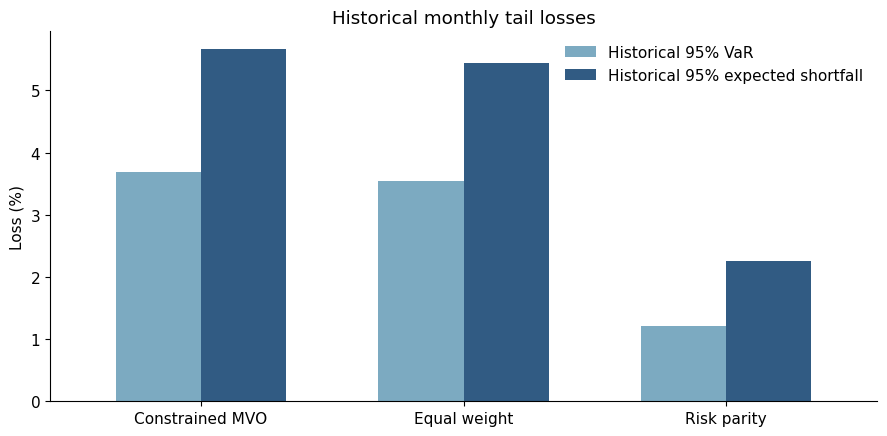

In [36]:
figure, axis = plt.subplots(figsize=(9, 4.5))
tail_chart = tail_risk[["historical_monthly_95pct_var", "historical_monthly_95pct_es"]] * 100
tail_chart.columns = ["Historical 95% VaR", "Historical 95% expected shortfall"]
tail_chart.plot.bar(ax=axis, rot=0, color=["#7caac1", "#315b83"], width=0.65)
axis.set(title="Historical monthly tail losses", ylabel="Loss (%)", xlabel="")
axis.legend(frameon=False)
save_chart(figure, "tail_risk")

## 11. Do the changes in weights materially change the portfolio?

A large reallocation does not necessarily imply a large change in estimated return or risk. We take all 32 allocations from Section 8 and evaluate them under the **original** return and covariance inputs. No new weights are fitted here.

The exact baseline is the reference for differences. The chosen rounded allocation is also shown, so the small rounding effect remains visible. Estimated volatility stays close to 8% by construction; we also compare risk shares, retrospective performance, monthly trading and the six existing stress scenarios.

The loss in estimated annual return is expressed in basis points

$$\Delta\mu_{bp}=10{,}000\left(\widehat\mu^\top w^{baseline}-\widehat\mu^\top w^{alternative}\right)$$

The risk-share reassignment measures how much risk moves between holdings

$$\text{risk reassigned}=\frac12\sum_i\left|RC_i^{alternative}-RC_i^{baseline}\right|$$

Historical comparisons use the same November 2016–September 2026 period, monthly rebalancing, initial investment charge and 10-basis-point cost per dollar traded. They remain retrospective sensitivity evidence. Stress scenarios keep the earlier gross-of-fees convention. We do not select a new portfolio from their historical results.

In [37]:
def stress_returns_for_weights(weights):
    scenario_returns = {}
    for scenario, (first_month, last_month) in historical_episodes.items():
        monthly_gross = returns.loc[first_month:last_month, ASSETS].to_numpy() @ weights
        scenario_returns[scenario] = float(np.prod(1 + monthly_gross) - 1)
    for scenario in hypothetical_shocks:
        scenario_returns[scenario] = float(weights @ hypothetical_shocks[scenario].to_numpy())
    return scenario_returns


comparison_weights = {"Exact baseline": exact_weights, "Chosen rounded weights": target_weights}
comparison_weights.update({label: row[ASSETS].to_numpy(dtype=float)
                           for label, row in mean_sensitivity.iterrows()})
original_baseline_return = float(study_means @ exact_weights)
baseline_risk_shares = risk_shares(exact_weights, study_covariance)
baseline_scenarios = stress_returns_for_weights(exact_weights)
materiality_rows = []
materiality_stress_rows = []
for label, weights in comparison_weights.items():
    allocation_risk = risk_shares(weights, study_covariance)
    simulation = simulate_fixed_weights(weights, study_evaluation)
    performance = performance_statistics(simulation["net_return"])
    annual_traded_fraction = simulation["traded_fraction"].iloc[1:].mean() * 12
    row = {
        "portfolio": label,
        "capital_reassigned_pct": float(abs(weights - exact_weights).sum() / 2 * 100),
        "estimated_return_original_inputs": float(study_means @ weights),
        "estimated_return_loss_bp": float((original_baseline_return - study_means @ weights) * 10_000),
        "estimated_volatility": portfolio_volatility(weights, study_covariance),
        "risk_reassigned_pct": float(abs(allocation_risk - baseline_risk_shares).sum() / 2 * 100),
        "combined_equity_risk_share": float(sum(allocation_risk[i] for i, a in enumerate(ASSETS)
                                                  if a in {"SPY", "VWO", "EEMV", "SCHD"})),
        "annual_traded_fraction_ex_inception": annual_traded_fraction,
        "annual_rebalance_cost_proxy_bp": annual_traded_fraction * TRADING_COST * 10_000,
        "historical_cagr": performance["cagr"],
        "historical_volatility": performance["volatility"],
        "historical_sharpe": performance["sharpe"],
        "historical_max_month_end_drawdown": performance["max_month_end_drawdown"],
        "historical_monthly_95pct_es": historical_expected_shortfall(simulation["net_return"]),
        **{ticker + "_weight": float(weights[i]) for i, ticker in enumerate(ASSETS)},
        **{ticker + "_risk_share": float(allocation_risk[i]) for i, ticker in enumerate(ASSETS)},
    }
    materiality_rows.append(row)
    for scenario, scenario_return in stress_returns_for_weights(weights).items():
        materiality_stress_rows.append({"portfolio": label, "scenario": scenario,
            "type": "historical" if scenario in historical_episodes else "hypothetical",
            "scenario_return": scenario_return,
            "change_from_exact_baseline_pp": (scenario_return - baseline_scenarios[scenario]) * 100,
            "pnl_usd_on_initial_capital": scenario_return * CAPITAL})
weight_materiality = pd.DataFrame(materiality_rows).set_index("portfolio")
weight_materiality_stress = pd.DataFrame(materiality_stress_rows)
weight_materiality.to_csv(STUDIES / "weight_change_materiality.csv")
weight_materiality_stress.to_csv(STUDIES / "weight_change_stress.csv", index=False)

illustrations = ["Exact baseline", "Chosen rounded weights", "VGSH +1 pp", "STIP -1 pp", "VWO +1 pp", "DBC -4 pp"]
display(weight_materiality.loc[illustrations,
    ["capital_reassigned_pct", "estimated_return_original_inputs", "estimated_return_loss_bp",
     "risk_reassigned_pct", "annual_rebalance_cost_proxy_bp"]]
    .rename(columns={"capital_reassigned_pct": "Capital moved (%)",
        "estimated_return_original_inputs": "Original-input estimated return",
        "estimated_return_loss_bp": "Estimated return loss (bp)",
        "risk_reassigned_pct": "Risk shares moved (%)",
        "annual_rebalance_cost_proxy_bp": "Annual rebalancing cost proxy (bp)"})
    .style.format({"Capital moved (%)": "{:.2f}", "Original-input estimated return": "{:.2%}",
                   "Estimated return loss (bp)": "{:.2f}", "Risk shares moved (%)": "{:.2f}",
                   "Annual rebalancing cost proxy (bp)": "{:.2f}"}))

,Capital moved (%),Original-input estimated return,Estimated return loss (bp),Risk shares moved (%),Annual rebalancing cost proxy (bp)
portfolio,,,,,
Exact baseline,0.00,9.28%,0.00,0.00,2.51
Chosen rounded weights,0.01,9.28%,0.06,0.01,2.51
VGSH +1 pp,28.84,9.22%,6.38,9.57,2.59
STIP -1 pp,24.14,9.23%,4.95,5.19,2.59
VWO +1 pp,11.54,9.21%,7.46,11.16,2.56
DBC -4 pp,4.85,9.27%,0.66,4.31,2.51


The annual rebalancing cost proxy multiplies average monthly purchases plus sales by twelve and the cost rate. It excludes the initial purchase and is expressed relative to contemporaneous portfolio value. It is a cost scale, not a forecast or the compounded difference between gross and net terminal wealth. Historical performance includes inception costs.

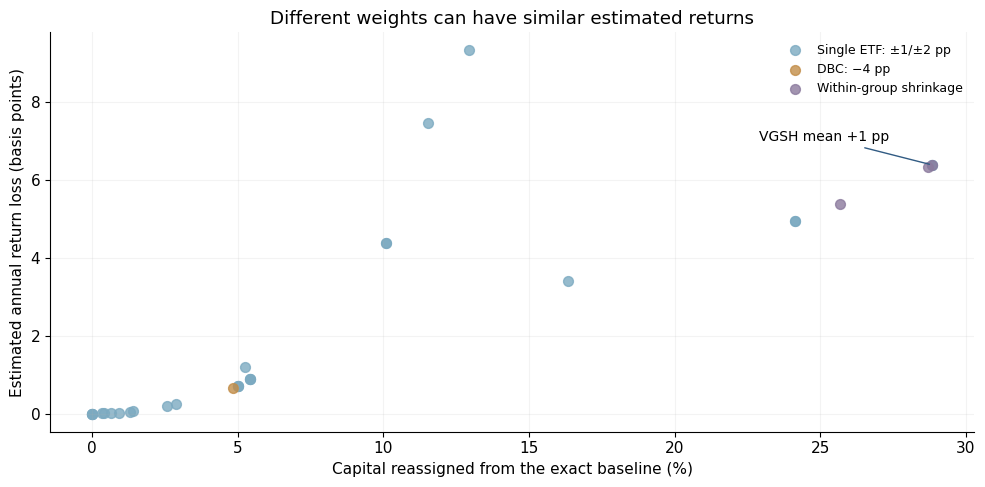

In [38]:
figure, axis = plt.subplots(figsize=(10, 5))
for kind, color, label in [("one_etf", "#7caac1", "Single ETF: ±1/±2 pp"),
                            ("larger_commodity_change", "#c28d48", "DBC: −4 pp"),
                            ("shrinkage", "#8b7a9d", "Within-group shrinkage")]:
    labels = mean_sensitivity.index[mean_sensitivity["kind"] == kind]
    points = weight_materiality.loc[labels]
    axis.scatter(points["capital_reassigned_pct"], points["estimated_return_loss_bp"],
                 color=color, s=50, alpha=0.8, label=label)
point = weight_materiality.loc["VGSH +1 pp"]
axis.annotate("VGSH mean +1 pp", (point.capital_reassigned_pct, point.estimated_return_loss_bp),
              xytext=(-125, 17), textcoords="offset points", fontsize=10,
              arrowprops={"arrowstyle": "-", "color": "#315b83"})
axis.set(title="Different weights can have similar estimated returns",
         xlabel="Capital reassigned from the exact baseline (%)",
         ylabel="Estimated annual return loss (basis points)")
axis.grid(alpha=0.15)
axis.legend(frameon=False, fontsize=9)
save_chart(figure, "weight_change_materiality")

### Compare risk shares and stress results

The following illustrations were selected to explain the existing input tests, not because they performed best historically. The risk chart uses the original 60-month covariance matrix. The stress table shows percentage-point changes from the exact baseline: positive values mean a better scenario return, and negative values mean a worse one. The hypothetical scenarios have no assigned probabilities or horizon.

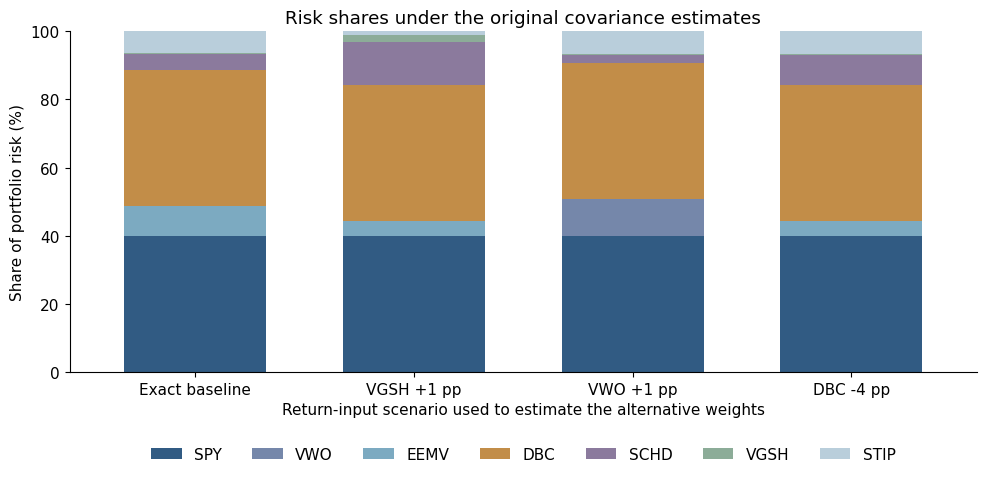

scenario,2018 Q4,2020 February–March,2022 calendar year,Growth shock,Commodity reversal,Inflation and rates shock
portfolio,,,,,,
Exact baseline,+0.00,+0.00,+0.00,+0.00,+0.00,+0.00
Chosen rounded weights,+0.00,+0.00,-0.00,-0.00,+0.00,-0.00
VGSH +1 pp,+0.07,+0.50,+0.34,+0.32,+0.85,+0.31
STIP -1 pp,+0.12,+0.19,-0.26,-0.12,+0.50,+0.30
VWO +1 pp,+0.02,+0.00,-0.34,-0.20,-0.03,-0.06
DBC -4 pp,-0.04,+0.20,+0.42,+0.31,+0.19,-0.01


The VGSH +1 pp case moves **28.84%** of capital, but reduces estimated annual return under the original inputs by **6.38 basis points**. Its risk-share reassignment is **9.57%**, and the largest absolute change among the six stress returns is **0.85 percentage points**.

Similar estimated mean and volatility do not establish that portfolios have identical economic exposures. The stress and risk-share comparisons help interpret the weight instability; they do not establish which allocation will work best in the next period.

In [39]:
risk_illustrations = ["Exact baseline", "VGSH +1 pp", "VWO +1 pp", "DBC -4 pp"]
risk_columns = [ticker + "_risk_share" for ticker in ASSETS]
risk_illustration_table = weight_materiality.loc[risk_illustrations, risk_columns].copy()
risk_illustration_table.columns = ASSETS
risk_visible_assets = [ticker for ticker in ASSETS if risk_illustration_table[ticker].abs().max() > 1e-8]
figure, axis = plt.subplots(figsize=(10, 5))
(risk_illustration_table[risk_visible_assets] * 100).plot.bar(stacked=True, ax=axis, rot=0,
    color=[ASSET_COLORS[ticker] for ticker in risk_visible_assets], width=0.65)
axis.set(title="Risk shares under the original covariance estimates", ylabel="Share of portfolio risk (%)",
         xlabel="Return-input scenario used to estimate the alternative weights", ylim=(0, 100))
axis.legend(ncol=len(risk_visible_assets), frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18))
save_chart(figure, "weight_change_risk_shares")
stress_difference_table = weight_materiality_stress.pivot(index="portfolio", columns="scenario",
    values="change_from_exact_baseline_pp").reindex(columns=[*historical_episodes, *hypothetical_shocks])
display(stress_difference_table.loc[illustrations].style.format("{:+.2f}"))
bond_case = weight_materiality.loc["VGSH +1 pp"]
bond_stress_changes = stress_difference_table.loc["VGSH +1 pp"]
display(Markdown(
    f"The VGSH +1 pp case moves **{bond_case.capital_reassigned_pct:.2f}%** of capital, but reduces estimated "
    f"annual return under the original inputs by **{bond_case.estimated_return_loss_bp:.2f} basis points**. "
    f"Its risk-share reassignment is **{bond_case.risk_reassigned_pct:.2f}%**, and the largest absolute change "
    f"among the six stress returns is **{bond_stress_changes.abs().max():.2f} percentage points**.\n\n"
    "Similar estimated mean and volatility do not establish that portfolios have identical economic exposures. "
    "The stress and risk-share comparisons help interpret the weight instability; they do not establish which "
    "allocation will work best in the next period."
))

## 12. How does realized volatility change through time?

We calculate trailing volatility from each portfolio's net monthly backtest returns. A point dated $t$ uses the latest $k$ observed monthly returns, ending at $t$

$$\widehat\sigma_{t}^{(k)}=\sqrt{12}\operatorname{sd}\left(r_{t-k+1}^{net}\ldots r_t^{net}\right)$$

The 12-month window responds more quickly to recent conditions. The 36-month window smooths those changes. Each uses sample standard deviation with $k-1$ in the denominator; no incomplete windows are filled in.

The shaded 7–9% band is a reference to the initial **ex-ante** budget. A historical rolling estimate outside it is not automatically a policy breach: it measures realized risk over a different window. The portfolios keep their current targets fixed, so the charts remain retrospective even though each rolling statistic uses only returns through its plotted date.

In [40]:
rolling_volatility = pd.DataFrame(index=backtest_returns.index)
rolling_risk_rows = []
for window in [12, 36]:
    for portfolio in backtest_returns:
        series = backtest_returns[portfolio].rolling(window, min_periods=window).std(ddof=1) * np.sqrt(12)
        rolling_volatility[f"{portfolio} {window}m"] = series
        observed = series.dropna()
        rolling_risk_rows.append({"portfolio": portfolio, "window_months": window,
            "windows": len(observed), "first_window_end": observed.index[0],
            "last_window_end": observed.index[-1], "minimum": observed.min(),
            "median": observed.median(), "maximum": observed.max(),
            "fraction_below_7pct": float((observed < 0.07).mean()),
            "fraction_between_7_and_9pct": float(observed.between(0.07, 0.09).mean()),
            "fraction_above_9pct": float((observed > 0.09).mean())})
rolling_risk_summary = pd.DataFrame(rolling_risk_rows)
rolling_volatility.to_csv(STUDIES / "rolling_volatility.csv", index_label="month")
rolling_risk_summary.to_csv(STUDIES / "rolling_volatility_summary.csv", index=False)
display(rolling_risk_summary.set_index(["portfolio", "window_months"])
    [["windows", "minimum", "median", "maximum", "fraction_below_7pct", "fraction_above_9pct"]]
    .rename(columns={"windows": "Complete windows", "minimum": "Minimum volatility",
        "median": "Median volatility", "maximum": "Maximum volatility",
        "fraction_below_7pct": "Fraction below 7%", "fraction_above_9pct": "Fraction above 9%"})
    .style.format({"Complete windows": "{:.0f}", "Minimum volatility": "{:.2%}",
        "Median volatility": "{:.2%}", "Maximum volatility": "{:.2%}",
        "Fraction below 7%": "{:.1%}", "Fraction above 9%": "{:.1%}"}))

,,Complete windows,Minimum volatility,Median volatility,Maximum volatility,Fraction below 7%,Fraction above 9%
portfolio,window_months,,,,,,
Constrained MVO,12,108,3.04%,7.60%,16.51%,46.3%,32.4%
Equal weight,12,108,2.43%,7.53%,15.76%,43.5%,27.8%
Risk parity,12,108,1.08%,3.04%,6.16%,100.0%,0.0%
Constrained MVO,36,84,5.26%,9.81%,12.26%,19.0%,56.0%
Equal weight,36,84,5.60%,9.43%,11.66%,20.2%,52.4%
Risk parity,36,84,2.44%,4.06%,4.92%,100.0%,0.0%


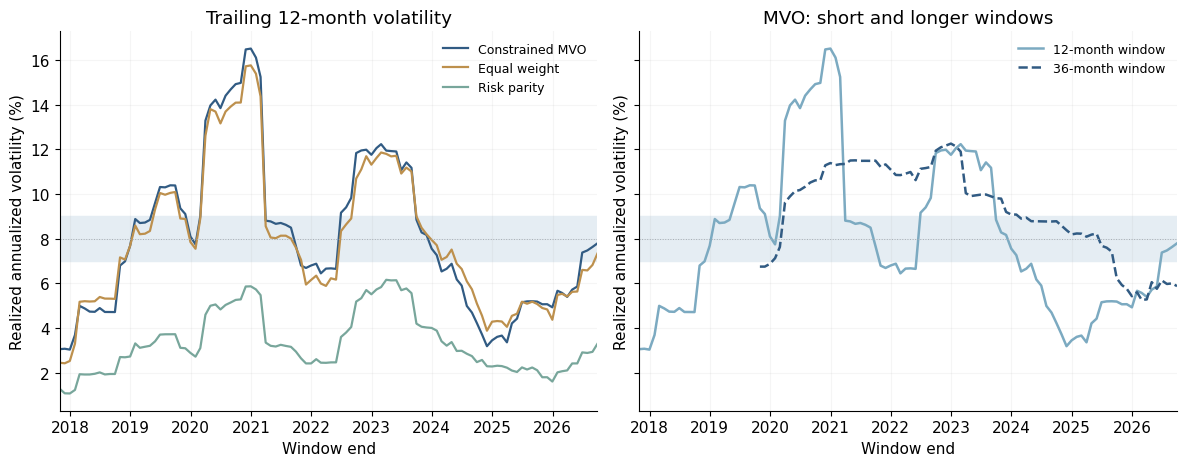

In [41]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
colors = {"Constrained MVO": "#315b83", "Equal weight": "#bd904d", "Risk parity": "#78a69b"}
for portfolio, color in colors.items():
    axes[0].plot(rolling_volatility.index, rolling_volatility[f"{portfolio} 12m"] * 100,
                 label=portfolio, color=color, lw=1.6)
for window, color, style in [(12, "#7caac1", "-"), (36, "#315b83", "--")]:
    axes[1].plot(rolling_volatility.index, rolling_volatility[f"Constrained MVO {window}m"] * 100,
                 label=f"{window}-month window", color=color, linestyle=style, lw=1.8)
for axis, title in zip(axes, ["Trailing 12-month volatility", "MVO: short and longer windows"]):
    axis.axhspan(7, 9, color="#e5edf3", zorder=0)
    axis.axhline(8, color="#a5adb5", lw=0.7, linestyle=":")
    axis.set(title=title, ylabel="Realized annualized volatility (%)", xlabel="Window end")
    axis.legend(frameon=False, fontsize=9)
    axis.grid(alpha=0.12)
    axis.set_xlim(rolling_volatility.dropna(how="all").index.min(), rolling_volatility.index.max())
save_chart(figure, "rolling_volatility")

## 13. Which ETFs produced the historical gains and losses?

We attribute the chosen rounded MVO backtest's dollar profit to ETF market returns and trading fees. The targets and 119-month period are the same as in the main notebook. This is return attribution; the earlier risk shares measure something different.

At the start of month $t$, let $V_{t-1}$ be portfolio value and $f_t=cT_t$ the fee fraction. Each ETF's dollar contribution is its return on the capital invested after paying fees

$$C_{i,t}=V_{t-1}(1-f_t)w_i r_{i,t}$$

$$C_{fees,t}=-V_{t-1}f_t$$

Summing across ETFs and fees gives that month's dollar profit. Summing through time gives final portfolio value minus initial capital. The table's percentage-point contributions are relative to the original USD 100 million; they are cumulative, not annualized returns.

The fee component records actual charges. It is not the compounded opportunity cost of those fees: a gross-versus-net terminal-value difference would also include foregone future growth.

In [42]:
def linked_return_attribution(weights, asset_returns, trading_cost=TRADING_COST, initial_capital=CAPITAL):
    portfolio_value = float(initial_capital)
    drifted_weights = np.zeros(len(weights))
    contribution_rows = []
    net_return_rows = []
    for month, observations in asset_returns.iterrows():
        traded_fraction = float(abs(weights - drifted_weights).sum())
        fee_fraction = trading_cost * traded_fraction
        market_components = (1 - fee_fraction) * weights * observations.to_numpy()
        components = np.r_[market_components, -fee_fraction]
        net_return = float(components.sum())
        contribution_rows.append(portfolio_value * components)
        net_return_rows.append(net_return)
        portfolio_value *= 1 + net_return
        gross_return = float(weights @ observations.to_numpy())
        drifted_weights = weights * (1 + observations.to_numpy()) / (1 + gross_return)
    contributions = pd.DataFrame(contribution_rows, index=asset_returns.index,
                                 columns=[*asset_returns.columns, "Trading costs"])
    return contributions, pd.Series(net_return_rows, index=asset_returns.index, name="net_return")


attribution_monthly, attribution_net_returns = linked_return_attribution(target_weights, study_evaluation)
chosen_simulation = simulate_fixed_weights(target_weights, study_evaluation)
assert np.allclose(attribution_net_returns, chosen_simulation["net_return"], atol=1e-12, rtol=0)
attribution_final_value = CAPITAL * (1 + attribution_net_returns).prod()
assert abs(attribution_monthly.to_numpy().sum() - (attribution_final_value - CAPITAL)) < 1e-5
attribution_totals = pd.DataFrame({
    "profit_contribution_usd": attribution_monthly.sum(),
    "cumulative_return_contribution_pp": attribution_monthly.sum() / CAPITAL * 100,
})
attribution_annual = attribution_monthly.groupby(attribution_monthly.index.year).sum()
attribution_monthly.to_csv(STUDIES / "monthly_return_attribution.csv", index_label="month")
attribution_totals.to_csv(STUDIES / "return_attribution_summary.csv", index_label="component")
attribution_annual.to_csv(STUDIES / "annual_return_attribution.csv", index_label="year")
visible_components = [ticker for ticker in ASSETS if allocation.loc[ticker, "target_weight"] > 1e-8] + ["Trading costs"]
display_attribution = attribution_totals.loc[visible_components].copy()
display_attribution.loc["Total profit"] = attribution_totals.sum()
display(display_attribution.rename(columns={"profit_contribution_usd": "Dollar profit contribution",
    "cumulative_return_contribution_pp": "Cumulative return contribution (pp)"})
    .style.format({"Dollar profit contribution": "${:,.2f}", "Cumulative return contribution (pp)": "{:+.2f}"}))
display(Markdown(f"The components sum to **USD {attribution_final_value - CAPITAL:,.2f}** of profit, "
    f"reconciling initial capital of USD {CAPITAL:,.0f} to final value of **USD {attribution_final_value:,.2f}**."))

,Dollar profit contribution,Cumulative return contribution (pp)
SPY,"$57,613,050.57",+57.61
EEMV,"$9,765,003.32",+9.77
DBC,"$49,131,225.74",+49.13
SCHD,"$5,952,499.45",+5.95
VGSH,"$1,301,813.03",+1.30
STIP,"$12,608,135.94",+12.61
Trading costs,"$-471,970.77",-0.47
Total profit,"$135,899,757.27",+135.90


The components sum to **USD 135,899,757.27** of profit, reconciling initial capital of USD 100,000,000 to final value of **USD 235,899,757.27**.

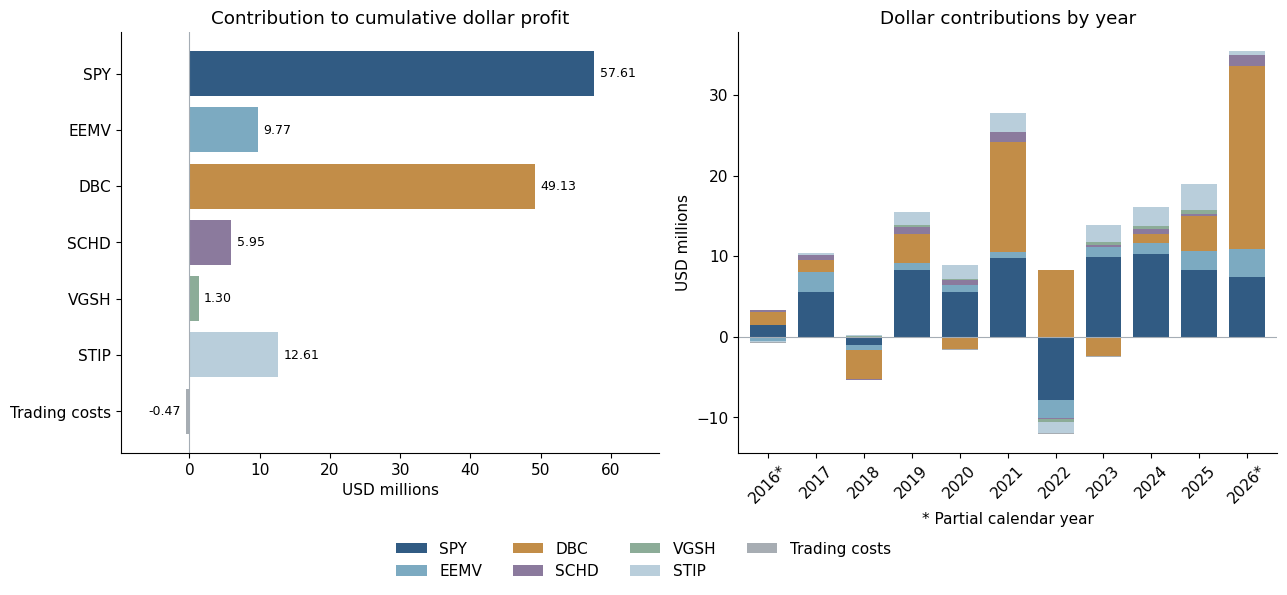

In [43]:
component_colors = ASSET_COLORS | {"Trading costs": "#a7adb3"}
figure, axes = plt.subplots(1, 2, figsize=(13, 5.5))
total_chart = attribution_totals.loc[visible_components, "profit_contribution_usd"] / 1_000_000
bars = axes[0].barh(total_chart.index, total_chart, color=[component_colors[c] for c in total_chart.index])
axes[0].bar_label(bars, fmt="%.2f", padding=4, fontsize=9)
axes[0].axvline(0, color="#a5adb5", lw=0.8)
axes[0].invert_yaxis()
axes[0].set(title="Contribution to cumulative dollar profit", xlabel="USD millions")
axes[0].margins(x=0.16)
annual_chart = attribution_annual[visible_components].copy() / 1_000_000
annual_chart.index = [f"{year}*" if year in [annual_chart.index.min(), annual_chart.index.max()] else str(year)
                      for year in annual_chart.index]
annual_chart.plot.bar(stacked=True, ax=axes[1], color=[component_colors[c] for c in visible_components],
                      width=0.75, rot=45, legend=False)
axes[1].axhline(0, color="#a5adb5", lw=0.8)
axes[1].set(title="Dollar contributions by year", ylabel="USD millions", xlabel="* Partial calendar year")
handles, labels = axes[1].get_legend_handles_labels()
figure.legend(handles, labels, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.09))
save_chart(figure, "return_attribution")

## Appendix. Backtest accounting

This optional calculation reproduces the main comparison using dollar holdings. At each month-start, it calculates trades and fees, invests the remaining capital at the target weights and applies that month's ETF returns. The resulting monthly returns should agree with the return formula in Section 3.

Risk shares are also calculated directly from each ETF's covariance with portfolio returns

$$RC_i=\frac{w_i\sigma_{ip}}{\sigma_p^2}$$

Here $\sigma_{ip}$ is the covariance between the ETF return and the portfolio return, and $\sigma_p^2$ is the portfolio return variance.

In [44]:
held_assets = [ticker for ticker in ["SPY", "EEMV", "DBC", "VGSH", "SCHD", "STIP"]
               if allocation.loc[ticker, "target_weight"] > 1e-8]
held_covariance = annual_covariance.loc[held_assets, held_assets].to_numpy()
benchmark_weights = {
    "Constrained MVO": allocation.loc[held_assets, "target_weight"].to_numpy(),
    "Equal weight": np.ones(len(held_assets)) / len(held_assets),
    "Risk parity": historical_parity(held_covariance),
}
evaluation = returns.loc[BACKTEST_START:, held_assets]
backtest_returns = pd.DataFrame({name: simulate_fixed_weights(weights, evaluation)["net_return"]
                                 for name, weights in benchmark_weights.items()})

In [45]:
accounting_checks = []
for name, weights in benchmark_weights.items():
    holdings = np.zeros(len(weights))
    nav = float(CAPITAL)
    independent_returns = []
    for _, observations in evaluation.iterrows():
        initial_nav = nav
        dollars_traded = np.abs(initial_nav * weights - holdings).sum()
        fee = TRADING_COST * dollars_traded
        holdings = (initial_nav - fee) * weights * (1 + observations.to_numpy())
        nav = float(holdings.sum())
        independent_returns.append(nav / initial_nav - 1)
    difference = np.max(abs(np.array(independent_returns) - backtest_returns[name].to_numpy()))
    assert difference < 1e-12
    accounting_checks.append([name, len(independent_returns), difference])
display(pd.DataFrame(accounting_checks, columns=["Portfolio", "Months checked", "Largest return difference"])
        .set_index("Portfolio").style.format({"Months checked": "{:.0f}", "Largest return difference": "{:.2e}"}))

direct_portfolio_returns = training.to_numpy() @ target_weights
direct_variance = np.var(direct_portfolio_returns, ddof=1) * 12
direct_shares = np.array([
    target_weights[i] * np.cov(training.iloc[:, i], direct_portfolio_returns, ddof=1)[0, 1] * 12 / direct_variance
    for i in range(len(ASSETS))
])
assert np.max(abs(direct_shares - allocation["risk_share"].to_numpy())) < 1e-10
assert policy_margins(target_weights, covariance, ASSETS, POLICY).min() >= -1e-10
assert abs(target_weights.sum() - 1) < 1e-12

,Months checked,Largest return difference
Portfolio,,
Constrained MVO,119,4.44e-16
Equal weight,119,4.44e-16
Risk parity,119,4.44e-16


## Saved results

All supporting tables and figures are in `studies/`. The figures above are saved as both PNG and PDF.

| Files | Contents |
|:--|:--|
| `constraint_sensitivity.csv` | Exact weights and risk shares for the 108 constraint settings |
| `constraint_backtest_context.csv` | Retrospective performance under those settings |
| `source_comparison.csv` | Bloomberg–Yahoo monthly return differences |
| `historical_fit_weights.csv` and `historical_fit_summary.csv` | Earlier estimated portfolios and subsequent performance |
| `trading_cost_sensitivity.csv` | Results at the three cost assumptions |
| `sharpe_bootstrap_interval.csv` | Conditional Sharpe interval |

| Additional files | Contents |
|:--|:--|
| `efficient_frontier.csv` and `minimum_risk_portfolio.csv` | Risk ceilings, search outcomes, frontier weights and the lowest-variance allocation found |
| `mean_input_scenarios.csv` and `mean_input_sensitivity.csv` | Modified annual means and the resulting allocations |
| `stress_scenario_assumptions.csv` | Explicit hypothetical ETF return shocks |
| `stress_summary.csv` and `stress_contributions.csv` | Historical and hypothetical results, including contributions by holding |
| `historical_stress_paths.csv` | Monthly portfolio values within the historical episodes |
| `tail_risk.csv` | Monthly historical VaR, expected shortfall and worst return |


| Follow-up files | Contents |
|:--|:--|
| `weight_change_materiality.csv` and `weight_change_stress.csv` | Original-input return and risk comparisons, cost scale and stress results for the existing input-test weights |
| `rolling_volatility.csv` and `rolling_volatility_summary.csv` | Complete trailing 12- and 36-month volatility windows and summaries |
| `monthly_return_attribution.csv`, `annual_return_attribution.csv` and `return_attribution_summary.csv` | ETF and fee contributions that reconcile to the chosen backtest's dollar profit |
